# Group 7 — Step 0: Clean, Join and Explore
**Urban Transit Dynamics and Extreme Weather · NYC and Chicago, 2017–2025**

One notebook for all three Phase 1 sources:

| Source | What | Dataset |
|---|---|---|
| A | MTA Subway Hourly Ridership (NYC), by station complex | NY Open Data `t69i-h2me` (2017–19), `wujg-7c2s` (2020–24), `5wq4-mkjj` (2025+) |
| B | CTA Daily Boarding Totals (bus + rail, systemwide) | Chicago Data Portal `6iiy-9s97` |
| B | CTA 'L' Station Entries, Daily Totals | Chicago Data Portal `5neh-572f` (+ `8pix-ypme` for station locations) |
| C | NOAA GHCN-Daily weather | NCEI Data Service API, 5 stations |

**How it's organized**
- **Part 1–3:** download and clean each source. Every decision is written to one shared `cleaning_log`, with a `source` column.
- **Part 4:** join everything on `city` + `date` (and nearest weather station for station-level data).
- **Part 5:** spot-check 20+ random rows from each source against the raw data.
- **Part 6–7:** analysis and the 6-chart briefing pack.

Run top to bottom. Raw downloads are cached in `data/raw/`, so re-runs are fast. `check()` stops the notebook with `CHECK FAILED` if anything is wrong.

In [137]:
import os, time, json, re
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

CLEAN_DIR = Path("data/clean"); CLEAN_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("figures");      FIG_DIR.mkdir(parents=True, exist_ok=True)

SOURCE = "SETUP"          # which dataset the next log entries belong to
CLEANING_LOG = []
def log(step, issue, rows, action, rejected):
    CLEANING_LOG.append(dict(source=SOURCE, step=step, issue=issue, rows_affected=int(rows),
                             action=action, alternative_rejected=rejected))
    print(f"[{SOURCE} {step}] {issue}: {int(rows):,} rows -> {action}")

def check(cond, msg):
    # Fail loudly: stop the notebook if a check fails.
    if not cond:
        raise AssertionError("CHECK FAILED: " + msg)
    print("  ✓", msg)

# Part 1 — NOAA GHCN-Daily weather (Source C)
Five stations: Central Park, LaGuardia and JFK for NYC; O'Hare and Midway for Chicago. The main station is used first and backups fill its gaps. Output is one row per city per day with extreme-weather flags, plus one row per station per day.

| Step | What it handles |
|---|---|
| 4a | duplicates |
| 4b | values that failed NOAA quality checks |
| 4c | trace amounts |
| 4d | missing days |
| 4e | impossible values |
| 4f | summer snow blanks |
| 4g | missing average temperature |
| 4h | decisions on record: units, timezone, real extremes |
| 5 | backup-station fills |
| 6 | flags |

In [138]:
SOURCE = "NOAA"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

START, END = "2016-12-01", "2025-12-31"

# station_id: (city, name, priority)   priority 1 = primary, used first; others fill gaps
STATIONS = {
    "USW00094728": ("NYC", "Central Park", 1),
    "USW00014732": ("NYC", "LaGuardia",    2),
    "USW00094789": ("NYC", "JFK",          3),
    "USW00094846": ("CHI", "O'Hare",       1),
    "USW00014819": ("CHI", "Midway",       2),
}

CORE = ["TMAX", "TMIN", "PRCP", "SNOW", "SNWD", "AWND"]   # analysis fields
OPTIONAL = ["TAVG", "WSF2", "WT03", "WT04", "WT06", "WT08"]  # nice-to-have
DATATYPES = CORE + OPTIONAL

RAW_DIR = Path("data/raw/noaa");   RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR = Path("data/clean");    CLEAN_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("figures");         FIG_DIR.mkdir(parents=True, exist_ok=True)

In [139]:
BASE = "https://www.ncei.noaa.gov/access/services/data/v1"

def fetch(station):
    out = RAW_DIR / f"{station}.csv"
    if out.exists() and out.stat().st_size > 0:
        return out
    params = dict(dataset="daily-summaries", stations=station, startDate=START, endDate=END,
                  dataTypes=",".join(DATATYPES), units="standard", includeAttributes="true",
                  includeStationName="true", includeStationLocation="1", format="csv")
    r = requests.get(BASE, params=params, timeout=180)
    r.raise_for_status()
    check(r.text.startswith('"STATION"') or r.text.startswith("STATION"),
          f"{station}: response looks like a CSV")
    out.write_text(r.text)
    time.sleep(1)
    return out

files = {s: fetch(s) for s in STATIONS}
files

{'USW00094728': WindowsPath('data/raw/noaa/USW00094728.csv'),
 'USW00014732': WindowsPath('data/raw/noaa/USW00014732.csv'),
 'USW00094789': WindowsPath('data/raw/noaa/USW00094789.csv'),
 'USW00094846': WindowsPath('data/raw/noaa/USW00094846.csv'),
 'USW00014819': WindowsPath('data/raw/noaa/USW00014819.csv')}

In [140]:
raw = pd.concat([pd.read_csv(p, dtype=str, keep_default_na=False) for p in files.values()],
                ignore_index=True)
raw_frozen = raw.copy()             # untouched copy for the spot-check
N_RAW = len(raw)
n_days = (pd.Timestamp(END) - pd.Timestamp(START)).days + 1

print("Raw rows:", N_RAW, "| expected if no days missing:", n_days * len(STATIONS))
print(raw.groupby("STATION").size().rename("rows"))
print("\nColumns:", list(raw.columns))
missing_types = [d for d in DATATYPES if d not in raw.columns]
print("Datatypes the API returned no column for:", missing_types)
check(set(raw["STATION"]) == set(STATIONS), "all 5 stations present in raw data")
raw.head()

Raw rows: 16589 | expected if no days missing: 16590
STATION
USW00014732    3318
USW00014819    3317
USW00094728    3318
USW00094789    3318
USW00094846    3318
Name: rows, dtype: int64

Columns: ['STATION', 'NAME', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'DATE', 'AWND', 'AWND_ATTRIBUTES', 'PRCP', 'PRCP_ATTRIBUTES', 'SNOW', 'SNOW_ATTRIBUTES', 'SNWD', 'SNWD_ATTRIBUTES', 'TAVG', 'TAVG_ATTRIBUTES', 'TMAX', 'TMAX_ATTRIBUTES', 'TMIN', 'TMIN_ATTRIBUTES', 'WSF2', 'WSF2_ATTRIBUTES', 'WT03', 'WT03_ATTRIBUTES', 'WT04', 'WT04_ATTRIBUTES', 'WT06', 'WT06_ATTRIBUTES', 'WT08', 'WT08_ATTRIBUTES']
Datatypes the API returned no column for: []
  ✓ all 5 stations present in raw data


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,AWND,AWND_ATTRIBUTES,PRCP,PRCP_ATTRIBUTES,SNOW,SNOW_ATTRIBUTES,SNWD,SNWD_ATTRIBUTES,TAVG,TAVG_ATTRIBUTES,TMAX,TMAX_ATTRIBUTES,TMIN,TMIN_ATTRIBUTES,WSF2,WSF2_ATTRIBUTES,WT03,WT03_ATTRIBUTES,WT04,WT04_ATTRIBUTES,WT06,WT06_ATTRIBUTES,WT08,WT08_ATTRIBUTES
0,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-01,7.61,",,W",0.07,",,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,54,",,W",42,",,W",19.9,",,W",,,,,,,,
1,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-02,8.72,",,W",0.00,",,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,51,",,W",40,",,W",17.0,",,W",,,,,,,,
2,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-03,8.72,",,W",0.00,"T,,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,47,",,W",41,",,W",17.0,",,W",,,,,,,,
3,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-04,4.92,",,W",0.00,",,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,47,",,W",39,",,W",12.1,",,W",,,,,,,,
4,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,42.7,2016-12-05,5.59,",,W",0.19,",,W,2400",0.0,",,W,2400",0.0,",,W,2400",,,49,",,W",38,",,W",15.0,",,W",,,,,,,,


In [141]:
df = raw.copy()
df["DATE"] = pd.to_datetime(df["DATE"], format="%Y-%m-%d", errors="raise")
VALUE_COLS = [d for d in DATATYPES if d in df.columns]

for c in VALUE_COLS:
    blank = df[c].str.strip() == ""
    df[c] = pd.to_numeric(df[c].where(~blank), errors="coerce")
    a = f"{c}_ATTRIBUTES"
    if a in df.columns:
        parts = df[a].str.split(",", expand=True).reindex(columns=range(4)).fillna("")
        df[f"{c}_M"] = parts[0].str.strip()
        df[f"{c}_Q"] = parts[1].str.strip()
        df[f"{c}_S"] = parts[2].str.strip()
        df = df.drop(columns=a)

df["city"] = df["STATION"].map(lambda s: STATIONS[s][0])
df["station_name"] = df["STATION"].map(lambda s: STATIONS[s][1])
df["priority"] = df["STATION"].map(lambda s: STATIONS[s][2])
for col in ["LATITUDE", "LONGITUDE", "ELEVATION"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
check(len(df) == N_RAW, "row count unchanged after parsing")

  ✓ row count unchanged after parsing


In [142]:
# 4a. Duplicate station-days
before = len(df)
dups = df.duplicated(["STATION", "DATE"], keep="first")
log("4a", "Duplicate STATION+DATE rows", dups.sum(),
    "Kept the first row, dropped the rest", "Averaging duplicates (hides a source problem)")
df = df[~dups].copy()
check(len(df) == before - dups.sum(), "row count = before minus duplicates")
check(not df.duplicated(["STATION", "DATE"]).any(), "STATION+DATE is now unique")

[NOAA 4a] Duplicate STATION+DATE rows: 0 rows -> Kept the first row, dropped the rest
  ✓ row count = before minus duplicates
  ✓ STATION+DATE is now unique


In [143]:
# 4b. Values that failed a NOAA quality check -> set to missing
for c in VALUE_COLS:
    q = f"{c}_Q"
    if q in df.columns:
        bad = (df[q] != "") & df[c].notna()
        if bad.any():
            log("4b", f"{c} failed NOAA quality check (qflag={sorted(df.loc[bad, q].unique())})",
                bad.sum(), "Set value to NaN (backup station can fill it later)",
                "Keeping flagged values / dropping the whole day")
            df.loc[bad, c] = np.nan
check(len(df) == N_RAW - dups.sum(), "4b: row count unchanged (values edited, no rows added or dropped)")

[NOAA 4b] TMAX failed NOAA quality check (qflag=['G', 'I']): 2 rows -> Set value to NaN (backup station can fill it later)
[NOAA 4b] TMIN failed NOAA quality check (qflag=['I', 'S']): 2 rows -> Set value to NaN (backup station can fill it later)
[NOAA 4b] SNWD failed NOAA quality check (qflag=['W']): 2 rows -> Set value to NaN (backup station can fill it later)
  ✓ 4b: row count unchanged (values edited, no rows added or dropped)


In [144]:
# 4c. Trace amounts: NOAA stores them as 0 with mflag 'T'. Keep the 0, add a flag column.
for c in ["PRCP", "SNOW"]:
    m = f"{c}_M"
    if m in df.columns:
        df[f"{c}_trace"] = df[m] == "T"
        log("4c", f"{c} trace amounts recorded as 0", df[f"{c}_trace"].sum(),
            f"Kept 0 and added a {c}_trace flag", "Imputing a small value like 0.01 in")
check(len(df) == N_RAW - dups.sum(), "4c: row count unchanged (values edited, no rows added or dropped)")

[NOAA 4c] PRCP trace amounts recorded as 0: 2,239 rows -> Kept 0 and added a PRCP_trace flag
[NOAA 4c] SNOW trace amounts recorded as 0: 581 rows -> Kept 0 and added a SNOW_trace flag
  ✓ 4c: row count unchanged (values edited, no rows added or dropped)


In [145]:
# 4d. Make the calendar complete: every station gets a row for every day
full_idx = pd.MultiIndex.from_product([list(STATIONS), pd.date_range(START, END, freq="D")],
                                      names=["STATION", "DATE"])
df = df.set_index(["STATION", "DATE"])
missing_days = full_idx.difference(df.index)
log("4d", "Station-days entirely missing from NOAA", len(missing_days),
    "Added empty rows (row_in_raw=False); backup station fills them at the city level",
    "Leaving gaps (they silently disappear in joins)")
df = df.reindex(full_idx)
df["row_in_raw"] = df["NAME"].notna() if "NAME" in df.columns else True
df = df.reset_index()
df["city"] = df["STATION"].map(lambda s: STATIONS[s][0])
df["station_name"] = df["STATION"].map(lambda s: STATIONS[s][1])
df["priority"] = df["STATION"].map(lambda s: STATIONS[s][2])
check(len(df) == n_days * len(STATIONS), "exactly one row per station per day")

[NOAA 4d] Station-days entirely missing from NOAA: 1 rows -> Added empty rows (row_in_raw=False); backup station fills them at the city level
  ✓ exactly one row per station per day


In [146]:
# 4e. Plausibility ranges (°F, inches, mph). Only physically impossible values are removed;
#     real extremes are the point of this project, so they stay.
RANGES = {"TMAX": (-30, 115), "TMIN": (-40, 100), "PRCP": (0, 15),
          "SNOW": (0, 40), "SNWD": (0, 60), "AWND": (0, 80)}
for c, (lo, hi) in RANGES.items():
    if c in df.columns:
        bad = df[c].notna() & ~df[c].between(lo, hi)
        log("4e", f"{c} outside plausible range [{lo}, {hi}]", bad.sum(),
            "Set to NaN", "Winsorizing / capping (would invent values)")
        df.loc[bad, c] = np.nan

check(len(df) == n_days * len(STATIONS), "4e: row count unchanged")
swap = df["TMAX"].notna() & df["TMIN"].notna() & (df["TMIN"] > df["TMAX"])
log("4e", "TMIN greater than TMAX on the same day", swap.sum(),
    "Set both to NaN", "Swapping them (we can't know which value is wrong)")
df.loc[swap, ["TMAX", "TMIN"]] = np.nan

# Show the most extreme days so a human can verify them against news/NWS records.
# Example: 2021-09-01 (remnants of Hurricane Ida) should show up as a top NYC rain day.
for c in ["PRCP", "SNOW", "TMAX"]:
    print(f"\nTop 5 {c} days by station:")
    print(df.nlargest(5, c)[["DATE", "station_name", c]].to_string(index=False))

[NOAA 4e] TMAX outside plausible range [-30, 115]: 0 rows -> Set to NaN
[NOAA 4e] TMIN outside plausible range [-40, 100]: 0 rows -> Set to NaN
[NOAA 4e] PRCP outside plausible range [0, 15]: 0 rows -> Set to NaN
[NOAA 4e] SNOW outside plausible range [0, 40]: 0 rows -> Set to NaN
[NOAA 4e] SNWD outside plausible range [0, 60]: 0 rows -> Set to NaN
[NOAA 4e] AWND outside plausible range [0, 80]: 0 rows -> Set to NaN
  ✓ 4e: row count unchanged
[NOAA 4e] TMIN greater than TMAX on the same day: 0 rows -> Set both to NaN

Top 5 PRCP days by station:
      DATE station_name  PRCP
2023-09-29          JFK  8.05
2021-09-01 Central Park  7.13
2021-09-01    LaGuardia  6.80
2023-09-29 Central Park  5.48
2017-10-14       Midway  5.20

Top 5 SNOW days by station:
      DATE station_name  SNOW
2021-02-01 Central Park  14.8
2021-02-01          JFK  11.9
2021-02-01    LaGuardia  11.7
2017-02-09    LaGuardia  10.0
2018-01-04 Central Park   9.8

Top 5 TMAX days by station:
      DATE station_name  TMAX

In [147]:
# 4f. Snowfall left blank in warm months. Many stations stop reporting SNOW in summer.
warm = df["DATE"].dt.month.isin([5, 6, 7, 8, 9])
for c in ["SNOW", "SNWD"]:
    fill = warm & df[c].isna() & df["row_in_raw"] & (df["TMIN"] > 35)
    log("4f", f"{c} blank in May–Sep on days with TMIN > 35°F", fill.sum(),
        "Filled with 0", "Filling every blank SNOW with 0 (would hide real winter gaps)")
    df.loc[fill, c] = 0
check(len(df) == n_days * len(STATIONS), "4f: row count unchanged (values edited, no rows added or dropped)")

[NOAA 4f] SNOW blank in May–Sep on days with TMIN > 35°F: 1,231 rows -> Filled with 0
[NOAA 4f] SNWD blank in May–Sep on days with TMIN > 35°F: 1,231 rows -> Filled with 0
  ✓ 4f: row count unchanged (values edited, no rows added or dropped)


In [148]:
# 4g. TAVG is often missing at these stations -> compute the midrange the standard way
if "TAVG" in df.columns:
    log("4g", "TAVG missing", df["TAVG"].isna().sum(),
        "Ignored raw TAVG; built TAVG_calc = (TMAX+TMIN)/2 for every day",
        "Mixing raw TAVG (hourly mean) with the midrange in one column")
df["TAVG_calc"] = (df["TMAX"] + df["TMIN"]) / 2

# Weather-type columns (WT**) are '1' when observed and blank otherwise: blank != 'did not happen'
for c in [w for w in ["WT03", "WT04", "WT06", "WT08"] if w in df.columns]:
    df[c] = df[c].fillna(0).astype(int)
station_day = df.copy()
check(len(df) == n_days * len(STATIONS), "4g: row count unchanged (values edited, no rows added or dropped)")

# 4h. Decisions that change no values but must be on record
log("4h", "Units: NOAA bulk files use tenths of °C and tenths of mm", N_RAW,
    "Requested units=standard from the API (°F, inches, mph); verified by the range checks in 4e",
    "Downloading metric bulk files and converting by hand (easy to get a factor of 10 wrong)")
log("4h", "Timezone: GHCN days run midnight to midnight local standard time; MTA data is hourly timestamps", 0,
    "Kept NOAA dates as local calendar dates; MTA hours must be summed by LOCAL date before joining",
    "Converting to UTC (would shift late-evening trips onto the next day)")
real_extremes = int((df["PRCP"] >= 3).sum() + (df["SNOW"] >= 8).sum() + (df["TMAX"] >= 100).sum())
log("4h", "Extreme but physically possible values (PRCP >= 3 in, SNOW >= 8 in, TMAX >= 100°F)", real_extremes,
    "Kept; top values checked against known storms (Ida 2021-09-01, JFK flood 2023-09-29, 2021-02-01 snowstorm)",
    "Removing outliers by z-score (would delete exactly the events this project studies)")
log("4h", "Source-flag columns (*_S) and raw TAVG not needed for analysis", N_RAW,
    "Left out of the saved files", "Keeping every column (clutters the table teammates join to)")
check(len(df) == n_days * len(STATIONS), "4h: row count unchanged")

[NOAA 4g] TAVG missing: 16,590 rows -> Ignored raw TAVG; built TAVG_calc = (TMAX+TMIN)/2 for every day
  ✓ 4g: row count unchanged (values edited, no rows added or dropped)
[NOAA 4h] Units: NOAA bulk files use tenths of °C and tenths of mm: 16,589 rows -> Requested units=standard from the API (°F, inches, mph); verified by the range checks in 4e
[NOAA 4h] Timezone: GHCN days run midnight to midnight local standard time; MTA data is hourly timestamps: 0 rows -> Kept NOAA dates as local calendar dates; MTA hours must be summed by LOCAL date before joining
[NOAA 4h] Extreme but physically possible values (PRCP >= 3 in, SNOW >= 8 in, TMAX >= 100°F): 50 rows -> Kept; top values checked against known storms (Ida 2021-09-01, JFK flood 2023-09-29, 2021-02-01 snowstorm)
[NOAA 4h] Source-flag columns (*_S) and raw TAVG not needed for analysis: 16,589 rows -> Left out of the saved files
  ✓ 4h: row count unchanged


In [149]:
VARS = [v for v in ["TMAX", "TMIN", "TAVG_calc", "PRCP", "SNOW", "SNWD", "AWND"] if v in df.columns]
city_rows = []
for city, g in df.sort_values("priority").groupby("city"):
    wide = {v: g.pivot(index="DATE", columns="priority", values=v) for v in VARS}
    out = pd.DataFrame(index=wide[VARS[0]].index)
    names = g.drop_duplicates("priority").set_index("priority")["station_name"]
    for v in VARS:
        w = wide[v]
        out[v] = w.bfill(axis=1).iloc[:, 0]
        src = w.notna().idxmax(axis=1).map(names).where(w.notna().any(axis=1))
        out[f"{v}_src"] = src
        filled = (src != names[1]) & src.notna()
        log("5", f"{city} {v}: primary missing, filled from backup", filled.sum(),
            "Used next-priority station", "Averaging all stations (blurs the primary record)")
        log("5", f"{city} {v}: missing at ALL stations", out[v].isna().sum(),
            "Left NaN", "Interpolating across days (weather isn't smooth)")
    for t in ["PRCP_trace", "SNOW_trace"]:
        if t in g.columns:
            out[t] = g[g.priority == 1].set_index("DATE")[t].fillna(False).astype(bool)
    out["city"] = city
    city_rows.append(out.reset_index())
city_day = pd.concat(city_rows, ignore_index=True).rename(columns={"DATE": "date"})
check(len(city_day) == 2 * n_days, "exactly 2 cities × every day")
check(not city_day.duplicated(["city", "date"]).any(), "city+date is unique (join key)")

[NOAA 5] CHI TMAX: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI TMAX: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI TMIN: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI TMIN: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI TAVG_calc: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI TAVG_calc: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI PRCP: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI PRCP: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI SNOW: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI SNOW: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI SNWD: primary missing, filled from backup: 0 rows -> Used next-priority station
[NOAA 5] CHI SNWD: missing at ALL stations: 0 rows -> Left NaN
[NOAA 5] CHI AWND: primary missing, filled from backup

In [150]:
cd = city_day
cd["year"] = cd["date"].dt.year
cd["month"] = cd["date"].dt.month
cd["dow"] = cd["date"].dt.day_name()
hol = USFederalHolidayCalendar().holidays(START, END)
cd["is_holiday"] = cd["date"].isin(hol)
cd["day_type"] = np.where(cd["is_holiday"] | (cd["date"].dt.dayofweek == 6), "U",
                  np.where(cd["date"].dt.dayofweek == 5, "A", "W"))   # matches CTA day_type codes
cd["period"] = pd.cut(cd["year"], bins=[2015, 2016, 2019, 2021, 2025],
                      labels=["buffer", "pre_covid", "covid", "post_covid"]).astype(str)

base = cd[cd["period"] == "pre_covid"]
TH = {}
for city in ["NYC", "CHI"]:
    b = base[base.city == city]
    TH[city] = dict(heat=b.loc[b.month.isin([6, 7, 8]), "TMAX"].quantile(.95),
                    cold=b.loc[b.month.isin([12, 1, 2]), "TMIN"].quantile(.05))
print("Thresholds (°F):", json.dumps({k: {kk: round(vv, 1) for kk, vv in v.items()} for k, v in TH.items()}))

cd["extreme_heat"] = cd.apply(lambda r: r.TMAX >= TH[r.city]["heat"], axis=1)
cd["extreme_cold"] = cd.apply(lambda r: r.TMIN <= TH[r.city]["cold"], axis=1)
cd["extreme_heat_abs"] = cd["TMAX"] >= 90
cd["extreme_cold_abs"] = cd["TMIN"] <= 10
cd["heavy_snow"] = cd["SNOW"] >= 4
# Added after first run: only ~12-16 days per city reach 4 in over 9 years, too few to compare periods.
# A 2-inch tier gives a larger sample; the group decides which one the analysis uses.
cd["snow_2in"] = cd["SNOW"] >= 2
log("6", "Heavy snow (>= 4 in) too rare to compare periods", int(cd["heavy_snow"].sum()),
    "Added a second tier snow_2in (>= 2 in); group to choose which one the analysis uses",
    "Lowering the heavy_snow threshold silently (would change the definition already in the Part 1 write-up)")
print("Days with SNOW >= 2 in:", cd[cd.period != "buffer"].groupby("city")["snow_2in"].sum().to_dict())
cd["heavy_rain"] = cd["PRCP"] >= 1.0
FLAGS = ["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]
cd["any_extreme"] = cd[FLAGS].any(axis=1)
# Comparisons need clean "normal" days; a day with no data shouldn't count as normal
cd["weather_complete"] = cd[["TMAX", "TMIN", "PRCP", "SNOW"]].notna().all(axis=1)
log("6", "Days lacking TMAX/TMIN/PRCP/SNOW after fills", (~cd["weather_complete"]).sum(),
    "Flagged weather_complete=False; exclude from 'normal day' baselines",
    "Treating missing as not-extreme")
city_day = cd
city_day.groupby(["city", "period"])[FLAGS].sum()

Thresholds (°F): {"NYC": {"heat": 92.0, "cold": 14.0}, "CHI": {"heat": 93.0, "cold": -1.0}}
[NOAA 6] Heavy snow (>= 4 in) too rare to compare periods: 30 rows -> Added a second tier snow_2in (>= 2 in); group to choose which one the analysis uses
Days with SNOW >= 2 in: {'CHI': 52, 'NYC': 28}
[NOAA 6] Days lacking TMAX/TMIN/PRCP/SNOW after fills: 0 rows -> Flagged weather_complete=False; exclude from 'normal day' baselines


extreme_heat  extreme_cold  heavy_snow  heavy_rain
city period                                                        
CHI  buffer                 0             3           2           0
     covid                 19             4           4          13
     post_covid            36            14           4          23
     pre_covid             26            16           4          34
NYC  buffer                 0             0           0           0
     covid                 19             2           4          22
     post_covid            36            15           2          43
     pre_covid             24            16          10          43

In [151]:
cd = city_day[city_day.period != "buffer"]
check(cd["date"].min() == pd.Timestamp("2017-01-01"), "analysis window starts 2017-01-01")
check(cd["date"].max() == pd.Timestamp("2025-12-31"), "analysis window ends 2025-12-31")
for city in ["NYC", "CHI"]:
    for v in ["TMAX", "TMIN", "PRCP"]:
        pct = city_day.loc[city_day.city == city, v].isna().mean() * 100
        check(pct < 2, f"{city} {v} missing {pct:.2f}% (< 2%)")
check(city_day["TMAX"].dropna().between(-30, 115).all(), "TMAX within plausible °F range")
check((city_day["TMIN"] <= city_day["TMAX"]).where(city_day[["TMIN", "TMAX"]].notna().all(axis=1), True).all(),
      "TMIN <= TMAX everywhere")
print("\nMissing % by column:")
print((city_day.isna().mean() * 100).round(2).loc[lambda s: s > 0])

  ✓ analysis window starts 2017-01-01
  ✓ analysis window ends 2025-12-31
  ✓ NYC TMAX missing 0.00% (< 2%)
  ✓ NYC TMIN missing 0.00% (< 2%)
  ✓ NYC PRCP missing 0.00% (< 2%)
  ✓ CHI TMAX missing 0.00% (< 2%)
  ✓ CHI TMIN missing 0.00% (< 2%)
  ✓ CHI PRCP missing 0.00% (< 2%)
  ✓ TMAX within plausible °F range
  ✓ TMIN <= TMAX everywhere

Missing % by column:
Series([], dtype: float64)


In [152]:
rng_sample = station_day[station_day["row_in_raw"]].sample(20, random_state=7)
rawk = raw_frozen.assign(DATE=pd.to_datetime(raw_frozen["DATE"])).set_index(["STATION", "DATE"])
rows = []
for _, r in rng_sample.iterrows():
    rr = rawk.loc[(r.STATION, r.DATE)]
    if isinstance(rr, pd.DataFrame):
        rr = rr.iloc[0]
    for v in ["TMAX", "TMIN", "PRCP", "SNOW"]:
        if v not in rawk.columns:
            continue
        raw_v = pd.to_numeric(rr[v], errors="coerce")
        new_v = r[v]
        same = (pd.isna(raw_v) and pd.isna(new_v)) or (raw_v == new_v)
        q = r.get(f"{v}_Q", "")
        reason = "" if same else ("failed quality flag" if isinstance(q, str) and q else
                                  "warm-month snow fill" if v == "SNOW" and new_v == 0 and pd.isna(raw_v) else
                                  "range/TMIN>TMAX fix" if pd.isna(new_v) else "UNEXPLAINED")
        rows.append(dict(station=r.station_name, date=r.DATE.date(), var=v,
                         raw=raw_v, clean=new_v, match=same, reason=reason))
spot = pd.DataFrame(rows)
print(f"Compared {len(spot)} values across 20 rows: {spot.match.sum()} exact matches, "
      f"{(~spot.match).sum()} differences")
print(spot[~spot.match].to_string(index=False) if (~spot.match).any() else "No differences.")
check((spot["reason"] != "UNEXPLAINED").all(), "every difference is explained by a logged step")
spot.head(20)
noaa_spot = spot   # keep: the MTA spot-check later reuses the name 'spot'

Compared 80 values across 20 rows: 79 exact matches, 1 differences
station       date  var  raw  clean  match               reason
 Midway 2017-05-03 SNOW  NaN    0.0  False warm-month snow fill
  ✓ every difference is explained by a logged step


In [153]:
keep_station = ["STATION", "station_name", "city", "LATITUDE", "LONGITUDE", "DATE", "row_in_raw"] + \
               [c for c in ["TMAX", "TMIN", "TAVG_calc", "PRCP", "SNOW", "SNWD", "AWND", "WSF2",
                            "PRCP_trace", "SNOW_trace", "WT03", "WT04", "WT06", "WT08"] if c in station_day.columns]
station_day[keep_station].to_csv(CLEAN_DIR / "noaa_station_day.csv", index=False)
city_day.to_csv(CLEAN_DIR / "noaa_city_day.csv", index=False)
cleaning_log = pd.DataFrame(CLEANING_LOG)
cleaning_log.to_csv(CLEAN_DIR / "noaa_cleaning_log.csv", index=False)
print(len(station_day), "station-day rows |", len(city_day), "city-day rows |", len(cleaning_log), "log entries")
cleaning_log

16590 station-day rows | 6636 city-day rows | 51 log entries


,source,step,issue,rows_affected,action,alternative_rejected
0,NOAA,4a,Duplicate STATION+DATE rows,0,"Kept the first row, dropped the rest",Averaging duplicates (hides a source problem)
1,NOAA,4b,"TMAX failed NOAA quality check (qflag=['G', 'I'])",2,Set value to NaN (backup station can fill it l...,Keeping flagged values / dropping the whole day
2,NOAA,4b,"TMIN failed NOAA quality check (qflag=['I', 'S'])",2,Set value to NaN (backup station can fill it l...,Keeping flagged values / dropping the whole day
3,NOAA,4b,SNWD failed NOAA quality check (qflag=['W']),2,Set value to NaN (backup station can fill it l...,Keeping flagged values / dropping the whole day
4,NOAA,4c,PRCP trace amounts recorded as 0,2239,Kept 0 and added a PRCP_trace flag,Imputing a small value like 0.01 in
5,NOAA,4c,SNOW trace amounts recorded as 0,581,Kept 0 and added a SNOW_trace flag,Imputing a small value like 0.01 in
6,NOAA,4d,Station-days entirely missing from NOAA,1,Added empty rows (row_in_raw=False); backup st...,Leaving gaps (they silently disappear in joins)
7,NOAA,4e,"TMAX outside plausible range [-30, 115]",0,Set to NaN,Winsorizing / capping (would invent values)
8,NOAA,4e,"TMIN outside plausible range [-40, 100]",0,Set to NaN,Winsorizing / capping (would invent values)
9,NOAA,4e,"PRCP outside plausible range [0, 15]",0,Set to NaN,Winsorizing / capping (would invent values)


In [154]:
# Join-key checks on the weather side (always run)
check(set(city_day["city"]) == {"NYC", "CHI"}, "city codes are exactly 'NYC' and 'CHI' (ridership tables must use the same codes)")
check(pd.api.types.is_datetime64_any_dtype(city_day["date"]), "date column is a real datetime, not text")
check((city_day["date"].dt.normalize() == city_day["date"]).all(), "dates have no time part (safe to join on calendar date)")

  ✓ city codes are exactly 'NYC' and 'CHI' (ridership tables must use the same codes)
  ✓ date column is a real datetime, not text
  ✓ dates have no time part (safe to join on calendar date)


# Part 2 — MTA subway ridership, NYC (Source A)
The NY Open Data server adds up hourly rows into **one row per station per day**, one week at a time, so we never download the raw hourly data (hundreds of millions of rows). Each dataset's real date range is checked first; for example, the 2017–2019 file starts on 2017-01-13.

In [155]:
SOURCE = "MTA"
M_START, M_END = "2017-01-01", "2025-12-31"
MTA_DATASETS = {  # label: (NY Open Data id, first date, last date)
    "2017-2019": ("t69i-h2me", "2017-01-01", "2019-12-31"),
    "2020-2024": ("wujg-7c2s", "2020-01-01", "2024-12-31"),
    "2025+":     ("5wq4-mkjj", "2025-01-01", "2025-12-31"),
}
APP_TOKEN = os.environ.get("SOCRATA_APP_TOKEN")   # optional free token: fewer rate limits
MTA_DIR = Path("data/raw/mta"); MTA_DIR.mkdir(parents=True, exist_ok=True)
BOROUGHS = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]

In [156]:
# Socrata API helpers (used for both NY Open Data and the Chicago Data Portal)
def soql(dataset, params, timeout=300, domain="data.ny.gov"):
    headers = {"X-App-Token": APP_TOKEN} if APP_TOKEN else {}
    for attempt in range(6):
        try:
            r = requests.get(f"https://{domain}/resource/{dataset}.json", params=params,
                             headers=headers, timeout=timeout)
        except (requests.exceptions.ConnectionError, requests.exceptions.Timeout,
                requests.exceptions.ChunkedEncodingError) as e:
            wait = 15 * (attempt + 1)
            print(f"      connection problem ({type(e).__name__}); retrying in {wait}s", flush=True)
            time.sleep(wait); continue
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503, 504):
            wait = 15 * (attempt + 1)
            print(f"      server busy (HTTP {r.status_code}); retrying in {wait}s", flush=True)
            time.sleep(wait); continue
        raise RuntimeError(f"{dataset}: HTTP {r.status_code}: {r.text[:500]}")
    raise RuntimeError(f"{dataset}: still failing after 6 tries; re-run the cell later to continue")

def soql_all(dataset, params, page=50000, domain="data.ny.gov"):
    rows, offset = [], 0
    while True:
        batch = soql(dataset, {**params, "$limit": page, "$offset": offset}, domain=domain)
        rows += batch
        if len(batch) < page:
            return rows
        offset += page

def probe_columns(dataset):
    # Return the field names present in one sample row
    return sorted(soql(dataset, {"$limit": 1})[0].keys())

def probe_range(dataset):
    # First and last timestamp actually present in the dataset
    r = soql(dataset, {"$select": "min(transit_timestamp) AS first, max(transit_timestamp) AS last"})[0]
    return pd.Timestamp(r["first"]), pd.Timestamp(r["last"])

def fetch_month(dataset, month, has_mode, chunk_days=7):
    # One month of daily totals per station, downloaded in week-long pieces; cached as CSV
    out = MTA_DIR / f"daily_{month}.csv"
    if out.exists() and out.stat().st_size > 0:
        return out
    mode = "transit_mode, " if has_mode else ""
    month_end = (month + 1).start_time
    edges = list(pd.date_range(month.start_time, month_end - pd.Timedelta(days=1), freq=f"{chunk_days}D")) + [month_end]
    rows = []
    for a, b in zip(edges[:-1], edges[1:]):          # pieces split at midnight, so no day is cut in half
        t0 = time.time()
        part = soql_all(dataset, {
            "$select": f"date_trunc_ymd(transit_timestamp) AS day, {mode}station_complex_id, station_complex, "
                       "borough, sum(ridership) AS ridership, count(*) AS n_raw_rows",
            "$where": f"transit_timestamp >= '{a:%Y-%m-%dT00:00:00}' AND transit_timestamp < '{b:%Y-%m-%dT00:00:00}'",
            "$group": f"day, {mode}station_complex_id, station_complex, borough",
            "$order": "day, station_complex_id"})
        rows += part
        print(f"      {a:%Y-%m-%d} to {b:%Y-%m-%d}: {len(part):,} rows in {time.time() - t0:.0f}s", flush=True)
    pd.DataFrame(rows).to_csv(out, index=False)
    time.sleep(1)
    return out

def fetch_station_meta(dataset=None):
    # Station coordinates from the small official 'MTA Subway Stations' table (39hk-dx4f, ~500 rows),
    # instead of scanning the huge hourly ridership data. Same station ID: complex_id = station_complex_id.
    out = MTA_DIR / "stations_39hk-dx4f.csv"
    if not (out.exists() and out.stat().st_size > 0):
        rows = soql_all("39hk-dx4f", {"$select": "complex_id, stop_name, borough, gtfs_latitude, gtfs_longitude"})
        pd.DataFrame(rows).to_csv(out, index=False)
        print(f"      station list: {len(rows)} stations downloaded", flush=True)
    m = pd.read_csv(out, dtype=str)
    return m.rename(columns={"complex_id": "station_complex_id", "gtfs_latitude": "latitude",
                             "gtfs_longitude": "longitude", "stop_name": "station_complex"})

def fetch_hourly_station_day(dataset, station_id, day):
    # Raw hourly rows for one station on one day (independent of the daily aggregation)
    d0 = pd.Timestamp(day); d1 = d0 + pd.Timedelta(days=1)
    rows = soql_all(dataset, {
        "$select": "transit_timestamp, ridership",
        "$where": f"station_complex_id = '{station_id}' AND transit_timestamp >= "
                  f"'{d0:%Y-%m-%dT00:00:00}' AND transit_timestamp < '{d1:%Y-%m-%dT00:00:00}'"})
    return pd.DataFrame(rows, columns=["transit_timestamp", "ridership"])

In [157]:
REQUIRED = {"transit_timestamp", "station_complex_id", "station_complex", "borough", "ridership"}
HAS_MODE = {}
for label, (ds, _, _) in MTA_DATASETS.items():
    cols = probe_columns(ds)
    print(f"{label} ({ds}) columns: {cols}")
    check(REQUIRED <= set(cols), f"{label}: has all required columns {sorted(REQUIRED)}")
    HAS_MODE[label] = "transit_mode" in cols

# Use each dataset's REAL date range (e.g. the 2017–2019 file may start after Jan 1, 2017)
RANGES = {}
for label, (ds, a, b) in MTA_DATASETS.items():
    first, last = probe_range(ds)
    RANGES[label] = (max(pd.Timestamp(a), first.normalize()), min(pd.Timestamp(b), last.normalize()))
    print(f"{label}: data runs {first:%Y-%m-%d} to {last:%Y-%m-%d}; using {RANGES[label][0]:%Y-%m-%d} to {RANGES[label][1]:%Y-%m-%d}")

months = {}
for label, (ds, _, _) in MTA_DATASETS.items():
    a, b = RANGES[label]
    if a <= b:
        for m in pd.period_range(a, b, freq="M"):
            months[m] = (label, ds)

files, t_all = [], time.time()
for i, (m, (label, ds)) in enumerate(months.items(), 1):
    cached = (MTA_DIR / f"daily_{m}.csv").exists()
    print(f"  {i:3d}/{len(months)}  {m}  {'cached' if cached else 'downloading...'}", flush=True)
    files.append((label, fetch_month(ds, m, HAS_MODE[label])))
    if not cached:
        print(f"           done (total {(time.time() - t_all) / 60:.1f} min)", flush=True)
print("Monthly files:", len(files))

2017-2019 (t69i-h2me) columns: ['borough', 'fare_class_category', 'georeference', 'latitude', 'longitude', 'payment_method', 'ridership', 'station_complex', 'station_complex_id', 'transfers', 'transit_mode', 'transit_timestamp']
  ✓ 2017-2019: has all required columns ['borough', 'ridership', 'station_complex', 'station_complex_id', 'transit_timestamp']
2020-2024 (wujg-7c2s) columns: [':@computed_region_kjdx_g34t', ':@computed_region_wbg7_3whc', ':@computed_region_yamh_8v7k', 'borough', 'fare_class_category', 'georeference', 'latitude', 'longitude', 'payment_method', 'ridership', 'station_complex', 'station_complex_id', 'transfers', 'transit_mode', 'transit_timestamp']
  ✓ 2020-2024: has all required columns ['borough', 'ridership', 'station_complex', 'station_complex_id', 'transit_timestamp']
2025+ (5wq4-mkjj) columns: ['borough', 'fare_class_category', 'georeference', 'latitude', 'longitude', 'payment_method', 'ridership', 'station_complex', 'station_complex_id', 'transfers', 'transi

In [158]:
parts = []
for label, p in files:
    try:
        d = pd.read_csv(p, dtype=str)
    except pd.errors.EmptyDataError:      # month with no data (e.g. early 2020): file is empty
        continue
    if len(d):
        d["source"] = label
        parts.append(d)
raw = pd.concat(parts, ignore_index=True)
if "transit_mode" not in raw.columns:
    raw["transit_mode"] = np.nan
raw_frozen = raw.copy()
N_RAW = len(raw)

df = raw.copy()
df["date"] = pd.to_datetime(df["day"].str[:10], format="%Y-%m-%d", errors="raise")
df["ridership"] = pd.to_numeric(df["ridership"], errors="coerce")
df["n_raw_rows"] = pd.to_numeric(df["n_raw_rows"], errors="coerce")
print("Raw daily rows:", f"{N_RAW:,}")
print(df.groupby("source").agg(rows=("date", "size"), first=("date", "min"), last=("date", "max")))

all_months = set(pd.period_range(M_START, M_END, freq="M"))
empty_months = sorted(all_months - set(df["date"].dt.to_period("M")))
covid_months = [m for m in empty_months if m.year in (2020, 2021)]
other_months = [m for m in empty_months if m.year not in (2020, 2021)]
log("3", "Months with no MTA data in COVID years 2020–21", len(covid_months),
    "Accepted: 2020–21 is excluded from comparisons anyway", "Treating as an error")
log("3", f"Months with no MTA data in 2017–19 / 2022–25: {[str(m) for m in other_months]}", len(other_months),
    "Accepted only if at the very start of the series (dataset begins later than 2017-01); recorded in datasheet",
    "Filling the gap with estimates")
check(len(other_months) <= 2, f"at most 2 missing months outside 2020–21 (missing: {[str(m) for m in other_months]})")
check(len(df) == N_RAW, "row count unchanged after parsing")

Raw daily rows: 1,394,773
             rows      first       last
source                                 
2017-2019  459497 2017-01-13 2019-12-31
2020-2024  780447 2020-01-01 2024-12-31
2025+      154829 2025-01-01 2025-12-31
[MTA 3] Months with no MTA data in COVID years 2020–21: 0 rows -> Accepted: 2020–21 is excluded from comparisons anyway
[MTA 3] Months with no MTA data in 2017–19 / 2022–25: []: 0 rows -> Accepted only if at the very start of the series (dataset begins later than 2017-01); recorded in datasheet
  ✓ at most 2 missing months outside 2020–21 (missing: [])
  ✓ row count unchanged after parsing


In [159]:
# 4a. Rows outside the dataset's own date range, and overlaps between datasets
bad_range = pd.Series(False, index=df.index)
for label, (_, a, b) in MTA_DATASETS.items():
    bad_range |= (df.source == label) & ~df.date.between(a, b)
log("4a", "Rows dated outside their dataset's declared range", bad_range.sum(),
    "Dropped", "Keeping them (would double-count overlap days)")
df = df[~bad_range].copy()
over = df.groupby(["date", "station_complex_id"])["source"].nunique()
check((over <= 1).all(), "no station-day appears in two datasets")

[MTA 4a] Rows dated outside their dataset's declared range: 0 rows -> Dropped
  ✓ no station-day appears in two datasets


In [160]:
# 4b. Transit mode: keep subway + Staten Island Railway (rail), drop Roosevelt Island Tram
before = len(df)
mode = df["transit_mode"].fillna("subway").str.strip().str.lower()
print(mode.value_counts())
tram = mode.str.contains("tram")
log("4b", "Roosevelt Island Tram rows", tram.sum(), "Dropped (aerial tram, not rail)",
    "Keeping (it isn't subway or rail service)")
log("4b", "Staten Island Railway rows", (mode.str.contains("staten") & ~tram).sum(),
    "Kept, flagged mode='sir', so Staten Island appears in the borough view",
    "Dropping SIR (would leave Staten Island out of Alex's borough breakdown)")
df["mode"] = np.where(mode.str.contains("staten"), "sir", "subway")
df = df[~tram].copy()
check(len(df) == before - tram.sum(), "row count = before minus tram rows")

transit_mode
subway                   1381680
tram                        6550
staten_island_railway       6543
Name: count, dtype: int64
[MTA 4b] Roosevelt Island Tram rows: 6,550 rows -> Dropped (aerial tram, not rail)
[MTA 4b] Staten Island Railway rows: 6,543 rows -> Kept, flagged mode='sir', so Staten Island appears in the borough view
  ✓ row count = before minus tram rows


In [161]:
# 4c. Station IDs and names: same station must have one ID across 2017–2025
df["station_id"] = df["station_complex_id"].astype(str).str.strip().str.upper()
ids_changed = (df["station_id"] != df["station_complex_id"]).sum()
log("4c", "Station IDs with stray spaces/lowercase", ids_changed, "Stripped and uppercased",
    "Leaving as-is (would break joins between datasets)")
names = df.groupby("station_id")["station_complex"].nunique()
renamed = names[names > 1]
log("4c", "Station IDs whose name differs between datasets", len(renamed),
    "Kept the ID as the key and used the most recent name", "Joining on names (renames would split one station into two)")
if len(renamed):
    print(df[df.station_id.isin(renamed.index[:10])].groupby(["station_id", "source"])["station_complex"].first().unstack())
latest = df.sort_values("date").groupby("station_id")["station_complex"].last()
df["station_name"] = df["station_id"].map(latest)

[MTA 4c] Station IDs with stray spaces/lowercase: 0 rows -> Stripped and uppercased
[MTA 4c] Station IDs whose name differs between datasets: 38 rows -> Kept the ID as the key and used the most recent name
source                              2017-2019                          2020-2024                         2025+
station_id                                                                                                    
221                    21 St-Queensbridge (F)             21 St-Queensbridge (F)        21 St-Queensbridge (M)
222                      Roosevelt Island (F)               Roosevelt Island (F)          Roosevelt Island (M)
223                  Lexington Av/63 St (F,Q)           Lexington Av/63 St (F,Q)      Lexington Av/63 St (M,Q)
224                                 57 St (F)                          57 St (F)                     57 St (M)
273                      Queens Plaza (E,M,R)               Queens Plaza (E,M,R)          Queens Plaza (E,F,R)
276              

In [162]:
# 4d. Borough names: standardize; fill blanks from the same station's other rows
BMAP = {"M": "Manhattan", "MANHATTAN": "Manhattan", "BK": "Brooklyn", "BROOKLYN": "Brooklyn",
        "Q": "Queens", "QUEENS": "Queens", "BX": "Bronx", "BRONX": "Bronx", "THE BRONX": "Bronx",
        "SI": "Staten Island", "STATEN ISLAND": "Staten Island"}
b = df["borough"].astype(str).str.strip().str.upper().map(BMAP)
nonstd = (df["borough"].astype(str).str.strip() != b) | df["borough"].isna()
log("4d", "Borough values not in a standard form (codes like 'BK', blanks, odd case)", nonstd.sum(),
    "Mapped codes like 'BK'/'M' to names; blanks filled from the station's most common borough",
    "Dropping rows with unknown borough")
common = b.groupby(df["station_id"]).agg(lambda s: s.mode().iat[0] if s.notna().any() else np.nan)
df["borough"] = b.fillna(df["station_id"].map(common))
check(df["borough"].isin(BOROUGHS).all(), "every row has one of the 5 boroughs")
check((df.groupby("station_id")["borough"].nunique() == 1).all(), "each station sits in exactly one borough")

[MTA 4d] Borough values not in a standard form (codes like 'BK', blanks, odd case): 0 rows -> Mapped codes like 'BK'/'M' to names; blanks filled from the station's most common borough
  ✓ every row has one of the 5 boroughs
  ✓ each station sits in exactly one borough


In [163]:
# 4e. Impossible ridership values
neg = df["ridership"] < 0
log("4e", "Negative daily ridership", neg.sum(), "Set to NaN", "Taking absolute value (invents data)")
df.loc[neg, "ridership"] = np.nan
miss = df["ridership"].isna()
log("4e", "Ridership missing/unparseable", miss.sum(), "Left NaN; excluded from analysis", "Filling with 0")

# 4f. One row per station per day (a station could appear twice if its name/borough text varied)
before = len(df)
df = (df.groupby(["date", "station_id"], as_index=False)
        .agg(ridership=("ridership", lambda s: s.sum(min_count=1)), n_raw_rows=("n_raw_rows", "sum"),
             station_name=("station_name", "first"), borough=("borough", "first"),
             mode=("mode", "first"), source=("source", "first")))
log("4f", "Rows merged into one station-day", before - len(df), "Summed ridership", "Keeping duplicates")
check(not df.duplicated(["date", "station_id"]).any(), "date + station_id is unique")

[MTA 4e] Negative daily ridership: 0 rows -> Set to NaN
[MTA 4e] Ridership missing/unparseable: 0 rows -> Left NaN; excluded from analysis
[MTA 4f] Rows merged into one station-day: 1 rows -> Summed ridership
  ✓ date + station_id is unique


In [164]:
# 4g. Complete calendar inside each station's active span; missing days stay NaN (closures, outages)
spans = df.groupby("station_id")["date"].agg(["min", "max"])
grid = pd.concat([pd.DataFrame({"station_id": s, "date": pd.date_range(r["min"], r["max"])})
                  for s, r in spans.iterrows()], ignore_index=True)
before = len(df)
df = grid.merge(df, on=["station_id", "date"], how="left", validate="one_to_one")
for c in ["station_name", "borough", "mode"]:
    df[c] = df.groupby("station_id")[c].transform("first")
df["missing_day"] = df["ridership"].isna()
log("4g", "Station-days with no record inside the station's active span", df["missing_day"].sum(),
    "Added as NaN rows (flag missing_day); not filled with 0",
    "Filling with 0 (a closed or unreported station is not zero riders)")
check(len(df) == len(grid), "row count = full station × day grid")

df["period"] = pd.cut(df.date.dt.year, [2016, 2019, 2021, 2025],
                      labels=["pre_covid", "covid", "post_covid"]).astype(str)
per = df[~df.missing_day].groupby("station_id")["period"].agg(set)
df["in_both_periods"] = df["station_id"].map(per.apply(lambda s: {"pre_covid", "post_covid"} <= s))
log("4g", "Stations missing from either 2017–19 or 2022–25",
    (~per.apply(lambda s: {"pre_covid", "post_covid"} <= s)).sum(),
    "Flagged in_both_periods=False; excluded from pre-vs-post comparisons",
    "Including them (station openings/closures would look like weather effects)")

[MTA 4g] Station-days with no record inside the station's active span: 6,774 rows -> Added as NaN rows (flag missing_day); not filled with 0
  ✓ row count = full station × day grid
[MTA 4g] Stations missing from either 2017–19 or 2022–25: 0 rows -> Flagged in_both_periods=False; excluded from pre-vs-post comparisons


In [165]:
# 4h. System-wide data outages: days where far fewer stations reported than usual
rep = df.groupby("date").agg(stations=("missing_day", lambda s: (~s).sum()),
                             total=("ridership", "sum"))
rep["typical"] = rep["stations"].rolling(29, center=True, min_periods=7).median()
rep["partial_day"] = rep["stations"] < 0.95 * rep["typical"]
log("4h", "Days where < 95% of the usual number of stations reported", rep["partial_day"].sum(),
    "Flagged partial_day; excluded from analysis as a data gap",
    "Treating low totals on those days as a weather effect")
print(rep[rep.partial_day].head(15))
df = df.merge(rep[["partial_day"]], left_on="date", right_index=True, how="left")

# Unusual system totals (storms OR data problems): flagged for a human to check, never dropped
dow_med = rep["total"].groupby(rep.index.dayofweek).transform(
    lambda s: s.rolling(9, center=True, min_periods=3).median())
rep["ratio"] = rep["total"] / dow_med
odd = rep[(rep.ratio < 0.6) | (rep.ratio > 1.4)]
log("4h", "Days with system total < 60% or > 140% of nearby same-weekday days", len(odd),
    "Kept; listed below to check against storms, holidays and outages",
    "Removing them (they are often exactly the weather days we study)")
print(odd[["stations", "total", "ratio"]].round(2).head(30))

[MTA 4h] Days where < 95% of the usual number of stations reported: 0 rows -> Flagged partial_day; excluded from analysis as a data gap
Empty DataFrame
Columns: [stations, total, typical, partial_day]
Index: []
[MTA 4h] Days with system total < 60% or > 140% of nearby same-weekday days: 55 rows -> Kept; listed below to check against storms, holidays and outages
            stations      total  ratio
date                                  
2017-02-09       423  3044925.0   0.53
2017-02-20       422  3298393.0   0.59
2017-03-14       423  1114537.0   0.19
2017-05-29       421  2310518.0   0.42
2017-07-04       419  2666291.0   0.48
2017-09-04       421  2618926.0   0.52
2017-11-23       421  2148579.0   0.36
2017-11-24       422  3488616.0   0.59
2017-12-25       421  1594845.0   0.30
2018-01-01       423  1908341.0   0.36
2018-01-04       422  2820103.0   0.51
2018-02-19       422  3097427.0   0.57
2018-03-21       421  3126279.0   0.55
2018-05-28       422  2464503.0   0.45
2018-07-04  

In [166]:
# 4i. Station-level spikes (events, e.g. New Year's Eve at Times Sq): flagged, kept
med = df.groupby("station_id")["ridership"].transform(lambda s: s.rolling(57, center=True, min_periods=10).median())
df["station_spike"] = df["ridership"] > 5 * med
log("4i", "Station-days above 5× the station's usual level", df["station_spike"].sum(),
    "Kept, flagged station_spike", "Capping (events are real riders)")
print(df[df.station_spike].nlargest(10, "ridership")[["date", "station_name", "ridership"]])
df["valid"] = ~df["missing_day"] & ~df["partial_day"].fillna(False)
log("4i", "Timezone: transit_timestamp is NYC local time; days summed by local calendar date", 0,
    "Kept local dates (matches NOAA's local-standard-time days); DST days have 23/25 hours",
    "Converting to UTC (would move late-night trips onto the next day)")

[MTA 4i] Station-days above 5× the station's usual level: 113 rows -> Kept, flagged station_spike
              date            station_name  ridership
1038979 2019-08-29  Mets-Willets Point (7)    43684.0
1035900 2020-03-12    Flushing-Main St (7)    42063.0
1038841 2019-04-13  Mets-Willets Point (7)    32513.0
1038827 2019-03-30  Mets-Willets Point (7)    29493.0
1041228 2025-10-25  Mets-Willets Point (7)    29488.0
1041249 2025-11-15  Mets-Willets Point (7)    27543.0
1040871 2024-11-02  Mets-Willets Point (7)    26717.0
1040857 2024-10-19  Mets-Willets Point (7)    26230.0
1038715 2018-12-08  Mets-Willets Point (7)    26186.0
1041235 2025-11-01  Mets-Willets Point (7)    26062.0
[MTA 4i] Timezone: transit_timestamp is NYC local time; days summed by local calendar date: 0 rows -> Kept local dates (matches NOAA's local-standard-time days); DST days have 23/25 hours


In [167]:
meta = pd.concat([fetch_station_meta(ds) for ds, _, _ in MTA_DATASETS.values()], ignore_index=True)
meta["station_id"] = meta["station_complex_id"].astype(str).str.strip().str.upper()
meta["lat"] = pd.to_numeric(meta["latitude"], errors="coerce")
meta["lon"] = pd.to_numeric(meta["longitude"], errors="coerce")
coords = meta.dropna(subset=["lat", "lon"]).groupby("station_id")[["lat", "lon"]].median()

wst = pd.read_csv(CLEAN_DIR / "noaa_station_day.csv", parse_dates=["DATE"])
wcoord = (wst[wst.city == "NYC"].dropna(subset=["LATITUDE"])
          .groupby("STATION")[["LATITUDE", "LONGITUDE", "station_name"]].first())

def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = (np.sin((lat2 - lat1) * p / 2) ** 2 +
         np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2)
    return 12742 * np.arcsin(np.sqrt(a))

dist = pd.DataFrame({w: haversine_km(coords.lat, coords.lon, r.LATITUDE, r.LONGITUDE)
                     for w, r in wcoord.iterrows()})
coords["noaa_station"] = dist.idxmin(axis=1)
coords["noaa_km"] = dist.min(axis=1).round(1)
mta_stations = df.groupby("station_id")[["station_name", "borough", "mode"]].first().join(coords)
no_xy = mta_stations["noaa_station"].isna()
log("5", "Stations with no coordinates", no_xy.sum(), "Assigned to Central Park",
    "Dropping them (loses riders)")
mta_stations.loc[no_xy, "noaa_station"] = "USW00094728"
far = mta_stations["noaa_km"] > 15
log("5", "Stations more than 15 km from their weather station", far.sum(),
    "Kept; flagged in noaa_km (mostly Staten Island / far Queens)", "Dropping them")
print(mta_stations.groupby(["borough", "noaa_station"]).size().unstack(fill_value=0))
print(mta_stations.groupby("borough")["noaa_km"].describe()[["mean", "max"]].round(1))
df = df.merge(mta_stations[["noaa_station", "noaa_km"]], left_on="station_id", right_index=True, how="left")

[MTA 5] Stations with no coordinates: 0 rows -> Assigned to Central Park
[MTA 5] Stations more than 15 km from their weather station: 52 rows -> Kept; flagged in noaa_km (mostly Staten Island / far Queens)
noaa_station   USW00014732  USW00094728  USW00094789
borough                                             
Bronx                   64            4            0
Brooklyn                19           98           39
Manhattan                4          117            0
Queens                  35           12           32
Staten Island            0            2            0
               mean   max
borough                  
Bronx           8.1  14.0
Brooklyn       13.1  19.8
Manhattan       4.9  10.9
Queens          6.1   9.9
Staten Island  17.8  18.1


In [168]:
wc = pd.read_csv(CLEAN_DIR / "noaa_city_day.csv", parse_dates=["date"])
wc = wc[wc.city == "NYC"].copy()
if "snow_2in" not in wc.columns:
    wc["snow_2in"] = wc["SNOW"] >= 2
check(not wc.duplicated("date").any(), "NOAA NYC table has one row per date")
WCOLS = ["date", "TMAX", "TMIN", "PRCP", "SNOW", "extreme_heat", "extreme_cold", "heavy_snow", "snow_2in",
         "heavy_rain", "weather_complete", "day_type", "dow", "is_holiday"]
before = len(df)
df = df.drop(columns=["period"]).merge(wc[WCOLS + ["period"]], on="date", how="left",
                                       validate="many_to_one", indicator=True)
unmatched = (df["_merge"] != "both").sum()
log("6", "Station-days with no matching weather day", unmatched, "Must be 0", "Dropping silently")
check(unmatched == 0, "every MTA date matched a NOAA date")
check(len(df) == before, "join kept the row count (no fan-out)")
df = df.drop(columns="_merge").rename(columns={"heavy_rain": "heavy_rain_city"})

local = wst[["STATION", "DATE", "PRCP"]].rename(columns={"STATION": "noaa_station", "DATE": "date", "PRCP": "PRCP_local"})
df = df.merge(local, on=["noaa_station", "date"], how="left", validate="many_to_one")
check(len(df) == before, "local-rain join kept the row count")
fb = df["PRCP_local"].isna()
log("6", "Station-days with no rain reading at the nearest weather station", fb.sum(),
    "Used the city (Central Park) rain value", "Dropping the day")
df["PRCP_local"] = df["PRCP_local"].fillna(df["PRCP"])
df["heavy_rain"] = df["PRCP_local"] >= 1.0
changed = (df["heavy_rain"] != df["heavy_rain_city"]).sum()
log("6", "Station-days where local heavy-rain flag differs from Central Park's", changed,
    "Used the local flag", "Using Central Park for every station (misses local flooding)")
df["any_extreme"] = df[["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]].any(axis=1)
mta_station_day = df

  ✓ NOAA NYC table has one row per date
[MTA 6] Station-days with no matching weather day: 0 rows -> Must be 0
  ✓ every MTA date matched a NOAA date
  ✓ join kept the row count (no fan-out)
  ✓ local-rain join kept the row count
[MTA 6] Station-days with no rain reading at the nearest weather station: 0 rows -> Used the city (Central Park) rain value
[MTA 6] Station-days where local heavy-rain flag differs from Central Park's: 12,784 rows -> Used the local flag


In [169]:
# Borough-day and city-day totals from valid station-days only
v = mta_station_day[mta_station_day.valid]
FLAGS_CITY = ["extreme_heat", "extreme_cold", "heavy_snow", "snow_2in", "weather_complete",
              "day_type", "dow", "is_holiday", "period", "TMAX", "SNOW"]
mta_borough_day = (v.groupby(["borough", "date"])
                 .agg(ridership=("ridership", "sum"), stations=("station_id", "nunique"),
                      heavy_rain=("heavy_rain", lambda s: s.mean() >= 0.5),   # most of the borough's stations
                      PRCP_local=("PRCP_local", "mean"))
                 .reset_index()
                 .merge(wc[["date"] + FLAGS_CITY], on="date", how="left", validate="many_to_one"))
mta_borough_day["any_extreme"] = mta_borough_day[["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]].any(axis=1)
log("6", "Borough heavy-rain rule", int(mta_borough_day["heavy_rain"].sum()),
    "A borough-day counts as heavy rain if most of its stations' nearest weather station had >= 1 in",
    "Using Central Park rain for all boroughs")
city_day_mta = (v.groupby("date").agg(ridership=("ridership", "sum")).reset_index()
                  .merge(wc, on="date", how="left", validate="one_to_one"))
check(len(mta_borough_day) == v.groupby(["borough", "date"]).ngroups, "one row per borough per day")
check(not city_day_mta.duplicated("date").any(), "one row per city-day")

[MTA 6] Borough heavy-rain rule: 532 rows -> A borough-day counts as heavy rain if most of its stations' nearest weather station had >= 1 in
  ✓ one row per borough per day
  ✓ one row per city-day


### MTA spot-check: 20 random station-days vs. their raw hourly rows (re-downloaded and added up independently)

In [170]:
sample = mta_station_day[mta_station_day.valid].sample(20, random_state=7)
ds_for = {label: ds for label, (ds, _, _) in MTA_DATASETS.items()}
mta_spot = None
rows = []
for _, r in sample.iterrows():
    ds = ds_for[r.source]
    hourly = fetch_hourly_station_day(ds, r.station_id, r.date)
    raw_sum = pd.to_numeric(hourly["ridership"], errors="coerce").sum()
    rows.append(dict(date=r.date.date(), station=r.station_name, borough=r.borough,
                     hourly_rows=len(hourly), raw_hourly_sum=round(raw_sum, 1),
                     cleaned=round(r.ridership, 1), match=abs(raw_sum - r.ridership) <= 0.5))
    time.sleep(0.5)
spot = mta_spot = pd.DataFrame(rows)
print(f"{spot.match.sum()} of {len(spot)} station-days match the raw hourly sum")
print(spot.to_string(index=False))
check(spot.match.all(), "every sampled station-day equals the sum of its raw hourly rows")

20 of 20 station-days match the raw hourly sum
      date                                       station   borough  hourly_rows  raw_hourly_sum  cleaned  match
2017-12-16                                  174 St (2,5)     Bronx          126          4598.0   4598.0   True
2025-09-09                              5 Av/53 St (E,F) Manhattan          176         16068.0  16068.0   True
2024-04-01                              Alabama Av (J,Z)  Brooklyn          159          1219.0   1219.0   True
2017-03-22 Broadway-Lafayette St/Bleecker St (6,B,D,F,M) Manhattan          132         38288.0  38288.0   True
2022-07-30                                  Brook Av (6)     Bronx          160          2118.0   2118.0   True
2023-05-26                     E 143 St-St Mary's St (6)     Bronx          125           849.0    849.0   True
2018-08-29                                 Junius St (3)  Brooklyn          117          1916.0   1916.0   True
2020-10-25                       Eastchester-Dyre Av (5) 

In [171]:
check(mta_station_day["date"].between(M_START, M_END).all(), "MTA: all dates within 2017–2025")
check(mta_station_day.loc[mta_station_day.valid, "ridership"].ge(0).all(), "MTA: no negative ridership in valid rows")
check(set(mta_borough_day["borough"]) <= set(BOROUGHS), "MTA: only the 5 boroughs appear")
for p in ["pre_covid", "post_covid"]:
    n = mta_station_day[(mta_station_day.period == p) & mta_station_day.valid]["station_id"].nunique()
    check(n > 300, f"MTA {p}: {n} stations with data (> 300)")
mta_station_day.to_csv(CLEAN_DIR / "mta_station_day.csv", index=False)
mta_borough_day.to_csv(CLEAN_DIR / "mta_borough_day.csv", index=False)
city_day_mta.to_csv(CLEAN_DIR / "mta_city_day.csv", index=False)
mta_stations.to_csv(CLEAN_DIR / "mta_stations.csv")
print(f"MTA saved: {len(mta_station_day):,} station-days, {len(mta_borough_day):,} borough-days")

  ✓ MTA: all dates within 2017–2025
  ✓ MTA: no negative ridership in valid rows
  ✓ MTA: only the 5 boroughs appear
  ✓ MTA pre_covid: 426 stations with data (> 300)
  ✓ MTA post_covid: 426 stations with data (> 300)
MTA saved: 1,394,996 station-days, 16,375 borough-days


# Part 3 — CTA ridership, Chicago (Source B)
Two tables from the Chicago Data Portal:
- **Daily Boarding Totals** (`6iiy-9s97`): one row per day, with systemwide `bus` and `rail_boardings`
- **'L' Station Entries** (`5neh-572f`): one row per station per day, `rides` = station entries

Rail *boardings* and station *entries* are different measures. Boardings also count cross-platform transfers, so entries should be a stable share of boardings, not equal to them. Step C9 uses this to cross-check the two tables.

Station locations come from the CTA 'L' stops list (`8pix-ypme`). They're used for two things:
- **Nearest weather station:** O'Hare or Midway.
- **Area:** each station is placed inside its official **community area** (Loop, Uptown, Hyde Park, ...) using the city's boundary file (`igwz-8jzy`). Community areas are then grouped into **North Side / Central / West Side / South Side**, following the city's usual "sides" convention. Suburban stations (Evanston, Oak Park, Rosemont, ...) lie outside the city's community areas, so they're assigned to the side they border, and this is logged.

If a download fails, the fallback is logged and the notebook keeps going.

In [172]:
SOURCE = "CTA"
CHI = "data.cityofchicago.org"
CTA_DIR = Path("data/raw/cta"); CTA_DIR.mkdir(parents=True, exist_ok=True)
CTA_SETS = {"daily": "6iiy-9s97", "stations": "5neh-572f", "stops": "8pix-ypme"}
C_START, C_END = "2017-01-01T00:00:00", "2025-12-31T23:59:59"

def cta_get(key, params, fname):
    out = CTA_DIR / fname
    if not (out.exists() and out.stat().st_size > 0):
        t0 = time.time()
        rows = soql_all(CTA_SETS[key], params, domain=CHI)
        pd.DataFrame(rows).to_csv(out, index=False)
        print(f"  downloaded {key}: {len(rows):,} rows in {time.time() - t0:.0f}s", flush=True)
    return pd.read_csv(out, dtype=str)

REQ_DAILY = {"service_date", "day_type", "bus", "rail_boardings", "total_rides"}
REQ_ST = {"station_id", "stationname", "date", "daytype", "rides"}
for key, req in [("daily", REQ_DAILY), ("stations", REQ_ST)]:
    cols = set(soql(CTA_SETS[key], {"$limit": 1}, domain=CHI)[0].keys())
    print(key, "columns:", sorted(cols))
    check(req <= cols, f"CTA {key}: has required columns {sorted(req)}")

cta_daily_raw = cta_get("daily", {"$where": f"service_date between '{C_START}' and '{C_END}'",
                                  "$order": "service_date"}, "cta_daily_2017_2025.csv")
cta_st_raw = cta_get("stations", {"$where": f"date between '{C_START}' and '{C_END}'",
                                  "$order": "date, station_id"}, "cta_station_entries_2017_2025.csv")
print(f"Raw CTA rows: daily {len(cta_daily_raw):,} | station-days {len(cta_st_raw):,}")
check(len(cta_daily_raw) > 3000, "CTA daily: at least ~3,000 days downloaded (9 years)")
check(len(cta_st_raw) > 100000, "CTA stations: at least 100,000 station-days downloaded")

daily columns: ['bus', 'day_type', 'rail_boardings', 'service_date', 'total_rides']
  ✓ CTA daily: has required columns ['bus', 'day_type', 'rail_boardings', 'service_date', 'total_rides']
stations columns: ['date', 'daytype', 'rides', 'station_id', 'stationname']
  ✓ CTA stations: has required columns ['date', 'daytype', 'rides', 'station_id', 'stationname']
Raw CTA rows: daily 3,287 | station-days 471,505
  ✓ CTA daily: at least ~3,000 days downloaded (9 years)
  ✓ CTA stations: at least 100,000 station-days downloaded


In [173]:
# C1. Parse types (dates come as '2017-01-01T00:00:00.000'; numbers as text)
d = cta_daily_raw.copy()
d["date"] = pd.to_datetime(d["service_date"].str[:10], format="%Y-%m-%d", errors="raise")
for c in ["bus", "rail_boardings", "total_rides"]:
    d[c] = pd.to_numeric(d[c], errors="coerce")
s = cta_st_raw.copy()
s["date"] = pd.to_datetime(s["date"].str[:10], format="%Y-%m-%d", errors="raise")
s["rides"] = pd.to_numeric(s["rides"], errors="coerce")
log("C1", "Unparseable numbers (daily bus/rail + station rides)",
    d[["bus", "rail_boardings"]].isna().sum().sum() + s["rides"].isna().sum(),
    "Left NaN", "Filling with 0")
check(len(d) == len(cta_daily_raw) and len(s) == len(cta_st_raw), "CTA: row counts unchanged after parsing")

# C2. Station IDs: join key with the stops list; must be the same text form in both
raw_id = s["station_id"].astype(str).str.strip()
s["station_id"] = raw_id.str.replace(r"\.0$", "", regex=True)
log("C2", "Station IDs stored as decimals like '40010.0'", (raw_id != s["station_id"]).sum(),
    "Converted to plain text IDs like '40010'", "Leaving as-is (would not match the stops list's map_id)")
check(s["station_id"].str.fullmatch(r"\d{5}").all(), "every CTA station_id is a 5-digit code")

[CTA C1] Unparseable numbers (daily bus/rail + station rides): 0 rows -> Left NaN
  ✓ CTA: row counts unchanged after parsing
[CTA C2] Station IDs stored as decimals like '40010.0': 0 rows -> Converted to plain text IDs like '40010'
  ✓ every CTA station_id is a 5-digit code


In [174]:
# C3. Duplicates
dup_d = d.duplicated("date", keep="first")
log("C3", "Duplicate dates in daily totals", dup_d.sum(), "Kept first", "Summing (would double-count)")
d = d[~dup_d].copy()
key = ["station_id", "date"]
dup_s = s.duplicated(key, keep=False)
same = s[dup_s].duplicated(key + ["rides"], keep=False).sum()
log("C3", f"Station-day rows appearing more than once ({same} of them identical copies)", dup_s.sum(),
    "Kept the first row of each station-day", "Summing (identical copies would double the count)")
s = s.drop_duplicates(key, keep="first")
check(not d.duplicated("date").any() and not s.duplicated(key).any(), "CTA: date / station+date are unique")

# C4. Station names: one ID can have several names over time
nm = s.groupby("station_id")["stationname"].nunique()
log("C4", "Station IDs with more than one name", (nm > 1).sum(), "Used the ID as key and the latest name",
    "Joining on names (renamed stations would split in two)")
s["station_name"] = s["station_id"].map(s.sort_values("date").groupby("station_id")["stationname"].last())

[CTA C3] Duplicate dates in daily totals: 0 rows -> Kept first
[CTA C3] Station-day rows appearing more than once (0 of them identical copies): 0 rows -> Kept the first row of each station-day
  ✓ CTA: date / station+date are unique
[CTA C4] Station IDs with more than one name: 0 rows -> Used the ID as key and the latest name


In [175]:
# C5. Zero / negative counts. A station with 0 entries all day was closed; that is not 'zero riders'
z = s["rides"] <= 0
log("C5", "Station-days with 0 or negative entries (closures)", z.sum(), "Set to NaN", "Keeping 0")
s.loc[z, "rides"] = np.nan
for c in ["bus", "rail_boardings"]:
    zd = d[c] <= 0
    log("C5", f"Days with {c} <= 0", zd.sum(), "Set to NaN", "Keeping 0")
    d.loc[zd, c] = np.nan

# C6. Complete calendars
full = pd.date_range("2017-01-01", "2025-12-31")
miss = full.difference(d["date"])
log("C6", "Calendar days missing from daily totals", len(miss), "Added as NaN rows", "Leaving gaps")
check(len(miss) <= 30, f"CTA daily: at most 30 missing days ({len(miss)})")
d = d.set_index("date").reindex(full).rename_axis("date").reset_index()
spans = s.groupby("station_id")["date"].agg(["min", "max"])
grid = pd.concat([pd.DataFrame({"station_id": i, "date": pd.date_range(r["min"], r["max"])})
                  for i, r in spans.iterrows()], ignore_index=True)
s = grid.merge(s, on=key, how="left", validate="one_to_one")
s["station_name"] = s.groupby("station_id")["station_name"].transform("first")
s["missing_day"] = s["rides"].isna()
log("C6", "Station-days with no entries record inside the station's active span", s["missing_day"].sum(),
    "Kept as NaN (flag missing_day)", "Filling with 0")
check(len(s) == len(grid), "CTA: row count = full station × day grid")

[CTA C5] Station-days with 0 or negative entries (closures): 4,153 rows -> Set to NaN
[CTA C5] Days with bus <= 0: 0 rows -> Set to NaN
[CTA C5] Days with rail_boardings <= 0: 0 rows -> Set to NaN
[CTA C6] Calendar days missing from daily totals: 0 rows -> Added as NaN rows
  ✓ CTA daily: at most 30 missing days (0)
[CTA C6] Station-days with no entries record inside the station's active span: 4,153 rows -> Kept as NaN (flag missing_day)
  ✓ CTA: row count = full station × day grid


In [176]:
# C7. Day type: CTA's own codes vs. our shared calendar (federal holidays) used for both cities
noaa_cd = pd.read_csv(CLEAN_DIR / "noaa_city_day.csv", parse_dates=["date"])
cal = noaa_cd[noaa_cd.city == "CHI"].set_index("date")["day_type"]
mism = d["day_type"].notna() & (d["day_type"] != d["date"].map(cal))
log("C7", "Days where CTA's day type differs from our federal-holiday calendar", mism.sum(),
    "Kept CTA code as cta_day_type; analysis uses the shared calendar so NYC and Chicago are treated alike",
    "Mixing CTA's codes for Chicago with our rule for NYC")
print(d.loc[mism, ["date", "day_type"]].assign(ours=d.loc[mism, "date"].map(cal)).head(10))
d = d.rename(columns={"day_type": "cta_day_type"})

# C8. Station-level outages: days with far fewer stations reporting than usual
rep = s.groupby("date").agg(stations_reporting=("missing_day", lambda x: (~x).sum()), entries=("rides", "sum"))
rep["typical"] = rep["stations_reporting"].rolling(29, center=True, min_periods=7).median()
rep["partial_day"] = rep["stations_reporting"] < 0.95 * rep["typical"]
log("C8", "Days where < 95% of usual 'L' stations reported", rep["partial_day"].sum(),
    "Flagged partial_day; excluded from station analysis", "Treating as a weather effect")
s = s.merge(rep[["partial_day"]], left_on="date", right_index=True, how="left")
s["valid"] = ~s["missing_day"] & ~s["partial_day"].fillna(False)

[CTA C7] Days where CTA's day type differs from our federal-holiday calendar: 41 rows -> Kept CTA code as cta_day_type; analysis uses the shared calendar so NYC and Chicago are treated alike
          date day_type ours
15  2017-01-16        W    U
50  2017-02-20        W    U
281 2017-10-09        W    U
313 2017-11-10        W    U
379 2018-01-15        W    U
414 2018-02-19        W    U
645 2018-10-08        W    U
680 2018-11-12        W    U
750 2019-01-21        W    U
778 2019-02-18        W    U
[CTA C8] Days where < 95% of usual 'L' stations reported: 2 rows -> Flagged partial_day; excluded from station analysis


In [177]:
# C9. Cross-check the two CTA tables: station entries should be a stable share of rail boardings
x = d.set_index("date")[["rail_boardings"]].join(rep[["entries", "partial_day"]])
x["ratio"] = x["entries"] / x["rail_boardings"]
x["ratio_typical"] = x["ratio"].rolling(57, center=True, min_periods=10).median()
x["off"] = (x["ratio"] / x["ratio_typical"] - 1).abs() > 0.15
print("Entries / boardings ratio by year (median):")
print(x.groupby(x.index.year)["ratio"].median().round(3).to_string())
log("C9", "Days where station entries / rail boardings is > 15% off its usual level", x["off"].sum(),
    "Flagged rail_check_off; listed below for review, kept", "Silently trusting either table")
print(x[x.off][["rail_boardings", "entries", "ratio", "ratio_typical"]].round(3).head(15))
d = d.merge(x[["off"]].rename(columns={"off": "rail_check_off"}), left_on="date", right_index=True, how="left")

# C10. 2025 counting change (Phase 1 limitation)
log("C10", "CTA changed how it estimates unpaid riders in 2025", int((d.date.dt.year == 2025).sum()),
    "Kept; flagged in datasheet. Our baselines compare each day only with normal days in the SAME year and month, "
    "so a level shift between years doesn't bias the % change", "Dropping 2025")

# C11. Unusual system totals (storms or data problems): listed, never dropped
for c in ["bus", "rail_boardings"]:
    dm = d.set_index("date")[c]
    med = dm.groupby(dm.index.dayofweek).transform(lambda t: t.rolling(9, center=True, min_periods=3).median())
    odd = (dm / med)[(dm / med < 0.6) | (dm / med > 1.4)]
    log("C11", f"Days with {c} < 60% or > 140% of nearby same-weekday days", len(odd),
        "Kept; check the list against storms, holidays and outages", "Removing them")
    print(odd.round(2).head(12).to_string())

Entries / boardings ratio by year (median):
date
2017    0.821
2018    0.821
2019    0.821
2020    0.821
2021    0.842
2022    0.843
2023    0.850
2024    0.850
2025    0.849
[CTA C9] Days where station entries / rail boardings is > 15% off its usual level: 0 rows -> Flagged rail_check_off; listed below for review, kept
Empty DataFrame
Columns: [rail_boardings, entries, ratio, ratio_typical]
Index: []
[CTA C10] CTA changed how it estimates unpaid riders in 2025: 365 rows -> Kept; flagged in datasheet. Our baselines compare each day only with normal days in the SAME year and month, so a level shift between years doesn't bias the % change
[CTA C11] Days with bus < 60% or > 140% of nearby same-weekday days: 67 rows -> Kept; check the list against storms, holidays and outages
date
2017-01-02    0.48
2017-05-29    0.46
2017-07-04    0.53
2017-09-04    0.49
2017-11-23    0.32
2017-12-25    0.21
2017-12-26    0.51
2017-12-27    0.58
2018-01-01    0.26
2018-02-09    0.60
2018-05-28    0.49
201

In [178]:
# C12. Station locations -> nearest Chicago weather station (O'Hare or Midway)
wst = pd.read_csv(CLEAN_DIR / "noaa_station_day.csv", parse_dates=["DATE"])
wchi = wst[wst.city == "CHI"].dropna(subset=["LATITUDE"]).groupby("STATION")[["LATITUDE", "LONGITUDE"]].first()
try:
    stops = pd.DataFrame(soql_all(CTA_SETS["stops"], {}, domain=CHI))
    def _ll(v):
        if isinstance(v, dict):
            if "latitude" in v: return float(v["latitude"]), float(v["longitude"])
            if "coordinates" in v: return float(v["coordinates"][1]), float(v["coordinates"][0])
        return np.nan, np.nan
    stops[["lat", "lon"]] = stops["location"].apply(lambda v: pd.Series(_ll(v)))
    stops["station_id"] = stops["map_id"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    cta_xy = stops.groupby("station_id")[["lat", "lon"]].mean()
except Exception as e:
    print("Stops list unavailable:", repr(e)[:200]); cta_xy = pd.DataFrame(columns=["lat", "lon"])
ids = pd.Index(s["station_id"].unique())
matched = ids.isin(cta_xy.index)
log("C12", "'L' stations not found in the stops list (no coordinates)", (~matched).sum(),
    "Assigned to O'Hare weather", "Dropping them")
xy = cta_xy.reindex(ids)
dist = pd.DataFrame({w: haversine_km(xy.lat, xy.lon, r.LATITUDE, r.LONGITUDE) for w, r in wchi.iterrows()})
has_xy = dist.notna().any(axis=1)
near = pd.Series("USW00094846", index=dist.index)          # fallback: O'Hare
near[has_xy] = dist[has_xy].idxmin(axis=1)
s["noaa_station"] = s["station_id"].map(near)

# Chicago areas: official community areas (Loop, Uptown, ...) from the city's boundary file,
# grouped into 4 sides. Suburban stations (Evanston, Oak Park, ...) lie outside every community area
# and are assigned to the side they border, using their latitude/longitude.
from matplotlib.path import Path as MPath
CTA_SETS["community_areas"] = "igwz-8jzy"
polys = []
try:
    ca = pd.DataFrame(soql_all(CTA_SETS["community_areas"], {}, domain=CHI))
    for _, r in ca.iterrows():
        g = r["the_geom"]
        g = json.loads(g) if isinstance(g, str) else g
        num = int(float(r["area_numbe"]))
        name = str(r["community"]).title().replace("'S", "'s")
        shapes = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        for shp in shapes:
            polys.append((num, name, MPath(np.array(shp[0])[:, :2])))      # outer ring, (lon, lat)
    check(ca.shape[0] == 77, "community-area boundary file has all 77 Chicago community areas")
except AssertionError:
    raise
except Exception as e:
    print("Community-area boundaries unavailable:", repr(e)[:200])

def community(lat, lon):
    if pd.isna(lat): return np.nan, "Unknown (no coordinates)"
    for num, name, p in polys:
        if p.contains_point((lon, lat)): return num, name
    return np.nan, "Outside Chicago"

# Community area number -> side (city's usual 'sides' convention, collapsed to 4 groups)
SIDE = {}
for n in [1, 2, 3, 4, 9, 10, 11, 12, 13, 14, 76, 77, 5, 6, 7, 21, 22, 15, 16, 17, 18, 19, 20]:
    SIDE[n] = "Chicago North Side"      # Far North, North, Northwest sides
for n in [8, 32, 33]:
    SIDE[n] = "Chicago Central"         # Near North Side, Loop, Near South Side
for n in range(23, 32):
    SIDE[n] = "Chicago West Side"
for n in list(range(34, 76)):
    SIDE.setdefault(n, "Chicago South Side")  # South, Southwest, Far Southeast, Far Southwest sides

def side_from_coords(lat, lon):        # only for suburban stations outside the city
    if lat > 41.91: return "Chicago North Side"
    if lat < 41.85: return "Chicago South Side"
    return "Chicago Central" if lon >= -87.66 else "Chicago West Side"

cta_st_lookup = []
for i in ids:
    lat, lon = xy.at[i, "lat"], xy.at[i, "lon"]
    num, name = community(lat, lon)
    if pd.notna(num):
        side, how = SIDE[int(num)], "community area"
    elif name == "Outside Chicago":
        side, how = side_from_coords(lat, lon), "bordering side (suburb)"
    else:
        side, how = "Unknown", "no coordinates"
    cta_st_lookup.append(dict(station_id=i, community_area=name, community_area_number=num, area=side, assigned_by=how))
cta_st_lookup = pd.DataFrame(cta_st_lookup).set_index("station_id")
cta_st_lookup["station_name"] = s.drop_duplicates("station_id").set_index("station_id")["station_name"]
cta_st_lookup["noaa_station"] = near
s["area"] = s["station_id"].map(cta_st_lookup["area"])
s["community_area"] = s["station_id"].map(cta_st_lookup["community_area"])
how = cta_st_lookup["assigned_by"].value_counts()
log("C12", "'L' stations placed in an official community area (point-in-polygon)", how.get("community area", 0),
    "Community area name kept; grouped into North Side / Central / West Side / South Side",
    "Hand-drawn latitude cut-offs for every station")
log("C12", "'L' stations outside Chicago city limits (Evanston, Oak Park, Rosemont, ...)", how.get("bordering side (suburb)", 0),
    "Assigned to the side they border, by latitude/longitude; flagged assigned_by='bordering side (suburb)'",
    "Dropping suburban stations (they are part of the CTA system)")
log("C12", "'L' stations with no coordinates", how.get("no coordinates", 0), "Area = 'Unknown'; left out of area charts", "Guessing")
print(cta_st_lookup["area"].value_counts().to_string())
print("\nCommunity areas in each group:")
print(cta_st_lookup.groupby("area")["community_area"].apply(lambda v: ", ".join(sorted(set(v))[:12])).to_string())
cta_st_lookup.to_csv(CLEAN_DIR / "cta_station_lookup.csv")
per = s[s.valid].assign(p=pd.cut(s.date.dt.year, [2016, 2019, 2021, 2025], labels=["pre", "covid", "post"]))
per = per.groupby("station_id")["p"].agg(lambda v: {"pre", "post"} <= set(v.astype(str)))
s["in_both_periods"] = s["station_id"].map(per).fillna(False)
log("C12", "'L' stations missing from either 2017–19 or 2022–25", int((~per).sum()),
    "Flagged in_both_periods=False; excluded from pre-vs-post comparisons", "Including them")
print(near.map({"USW00094846": "O'Hare", "USW00014819": "Midway"}).value_counts())
cta_daily, cta_station_day = d, s
cta_daily.to_csv(CLEAN_DIR / "cta_daily.csv", index=False)

[CTA C12] 'L' stations not found in the stops list (no coordinates): 2 rows -> Assigned to O'Hare weather
  ✓ community-area boundary file has all 77 Chicago community areas
[CTA C12] 'L' stations placed in an official community area (point-in-polygon): 124 rows -> Community area name kept; grouped into North Side / Central / West Side / South Side
[CTA C12] 'L' stations outside Chicago city limits (Evanston, Oak Park, Rosemont, ...): 20 rows -> Assigned to the side they border, by latitude/longitude; flagged assigned_by='bordering side (suburb)'
[CTA C12] 'L' stations with no coordinates: 2 rows -> Area = 'Unknown'; left out of area charts
area
Chicago North Side    51
Chicago West Side     43
Chicago Central       25
Chicago South Side    25
Unknown                2

Community areas in each group:
area
Chicago Central                  Loop, Near North Side, Near South Side
Chicago North Side    Albany Park, Avondale, Edgewater, Irving Park,...
Chicago South Side    Armour Square, Bri

# Part 4 — Join everything
**Key:** `city` + `date`. The weather tables use the codes `NYC`/`CHI` and real datetime dates, both checked in Part 1.

- **`mode_day`**: one row per city, mode and day for NYC subway, Chicago rail and Chicago bus, joined to that city's weather and calendar.
- **`station_all`**: one row per station per day for NYC subway stations and Chicago 'L' stations. Heavy rain uses each station's *nearest* weather station, because rain is local.

Each join is checked: every ridership day must match exactly one weather day, and row counts must not change.

In [179]:
SOURCE = "JOIN"
wc_all = pd.read_csv(CLEAN_DIR / "noaa_city_day.csv", parse_dates=["date"])
WC = ["date", "city", "TMAX", "TMIN", "PRCP", "SNOW", "extreme_heat", "extreme_cold", "heavy_snow", "snow_2in",
      "heavy_rain", "any_extreme", "weather_complete", "day_type", "dow", "is_holiday", "period"]
wc_all = wc_all[[c for c in WC if c in wc_all.columns]]
if "snow_2in" not in wc_all: wc_all["snow_2in"] = wc_all["SNOW"] >= 2
check(not wc_all.duplicated(["city", "date"]).any(), "weather: one row per city per day")

parts = [city_day_mta[["date", "ridership"]].assign(city="NYC", mode="NYC subway"),
         cta_daily[["date", "rail_boardings"]].rename(columns={"rail_boardings": "ridership"}).assign(city="CHI", mode="Chicago rail"),
         cta_daily[["date", "bus"]].rename(columns={"bus": "ridership"}).assign(city="CHI", mode="Chicago bus")]
long = pd.concat(parts, ignore_index=True)
long = long[long.date.between("2017-01-01", "2025-12-31")]
n0 = len(long)
mode_day = long.merge(wc_all, on=["city", "date"], how="left", validate="many_to_one", indicator=True)
unm = (mode_day["_merge"] != "both").sum()
log("J1", "Ridership days (all 3 modes) with no weather match", unm, "Must be 0", "Dropping silently")
check(unm == 0, "every ridership day matched a weather day")
check(len(mode_day) == n0, f"mode_day row count unchanged by the join ({n0:,})")
mode_day = mode_day.drop(columns="_merge")
mode_day["valid"] = mode_day["ridership"].notna()
print(mode_day.groupby("mode").agg(days=("date", "size"), first=("date", "min"), last=("date", "max"),
                                   missing=("valid", lambda v: (~v).sum())))

  ✓ weather: one row per city per day
[JOIN J1] Ridership days (all 3 modes) with no weather match: 0 rows -> Must be 0
  ✓ every ridership day matched a weather day
  ✓ mode_day row count unchanged by the join (9,849)
              days      first       last  missing
mode                                             
Chicago bus   3287 2017-01-01 2025-12-31        0
Chicago rail  3287 2017-01-01 2025-12-31        0
NYC subway    3275 2017-01-13 2025-12-31        0


In [180]:
# Station-level table for both cities
nyc_st = mta_station_day[mta_station_day.valid & mta_station_day.in_both_periods][
    ["date", "station_id", "station_name", "borough", "ridership", "noaa_station", "PRCP_local", "heavy_rain"]
].rename(columns={"borough": "area"}).assign(city="NYC")
chi = cta_station_day[cta_station_day.valid & cta_station_day.in_both_periods][
    ["date", "station_id", "station_name", "rides", "noaa_station", "area"]]
chi = chi.rename(columns={"rides": "ridership"}).assign(city="CHI")
loc = wst[["STATION", "DATE", "PRCP"]].rename(columns={"STATION": "noaa_station", "DATE": "date", "PRCP": "PRCP_local"})
n0 = len(chi)
chi = chi.merge(loc, on=["noaa_station", "date"], how="left", validate="many_to_one")
check(len(chi) == n0, "Chicago local-rain join kept the row count")
chi_city = wc_all[wc_all.city == "CHI"].set_index("date")["PRCP"]
fb = chi["PRCP_local"].isna()
log("J2", "Chicago station-days with no rain reading at nearest weather station", fb.sum(),
    "Used O'Hare (city) rain", "Dropping the day")
chi["PRCP_local"] = chi["PRCP_local"].fillna(chi["date"].map(chi_city))
chi["heavy_rain"] = chi["PRCP_local"] >= 1.0

st = pd.concat([nyc_st, chi], ignore_index=True)
n0 = len(st)
station_all = st.merge(wc_all.drop(columns=["heavy_rain", "any_extreme"]), on=["city", "date"],
                       how="left", validate="many_to_one", indicator=True)
unm = (station_all["_merge"] != "both").sum()
log("J3", "Station-days (both cities) with no weather match", unm, "Must be 0", "Dropping silently")
check(unm == 0, "every station-day matched a weather day")
check(len(station_all) == n0, "station join kept the row count")
station_all = station_all.drop(columns="_merge")
station_all["any_extreme"] = station_all[["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]].any(axis=1)
print(station_all.groupby("city")["station_id"].nunique().rename("stations"))

  ✓ Chicago local-rain join kept the row count
[JOIN J2] Chicago station-days with no rain reading at nearest weather station: 885 rows -> Used O'Hare (city) rain
[JOIN J3] Station-days (both cities) with no weather match: 0 rows -> Must be 0
  ✓ every station-day matched a weather day
  ✓ station join kept the row count
city
CHI    143
NYC    426
Name: stations, dtype: int64


# Part 5 — Spot-checks against the raw data
AI wrote this pipeline, so each source is checked against its raw data. The NOAA spot-check ran in Part 1 (20 station-days, 80 values) and the MTA one in Part 2 (20 station-days re-downloaded hourly). Here are the CTA checks, and a summary of all of them for the report.

In [181]:
SOURCE = "CTA"
raw_s = cta_st_raw.assign(date=pd.to_datetime(cta_st_raw["date"].str[:10]),
                          station_id=cta_st_raw["station_id"].astype(str).str.replace(r"\.0$", "", regex=True))
raw_s["rides"] = pd.to_numeric(raw_s["rides"], errors="coerce")
first_raw = raw_s.drop_duplicates(["station_id", "date"]).set_index(["station_id", "date"])["rides"]
samp = cta_station_day[cta_station_day.valid].sample(20, random_state=7)
cs = pd.DataFrame(dict(station=samp.station_name.values, date=samp.date.dt.date.values,
                       raw=[first_raw.get((i, t)) for i, t in zip(samp.station_id, samp.date)],
                       cleaned=samp.rides.values))
cs["match"] = cs["raw"] == cs["cleaned"]
raw_d = cta_daily_raw.assign(date=pd.to_datetime(cta_daily_raw["service_date"].str[:10]))
raw_d = raw_d.drop_duplicates("date").set_index("date")
sd = cta_daily.dropna(subset=["bus", "rail_boardings"]).sample(20, random_state=7)
cd2 = pd.DataFrame(dict(date=sd.date.dt.date.values,
                        raw_bus=pd.to_numeric(raw_d.loc[sd.date, "bus"]).values, bus=sd.bus.values,
                        raw_rail=pd.to_numeric(raw_d.loc[sd.date, "rail_boardings"]).values, rail=sd.rail_boardings.values))
cd2["match"] = (cd2.raw_bus == cd2.bus) & (cd2.raw_rail == cd2.rail)
print(f"CTA station-days: {cs.match.sum()} of 20 match raw | CTA daily totals: {cd2.match.sum()} of 20 match raw")
print(cs.to_string(index=False)); print(cd2.to_string(index=False))
check(cs.match.all() and cd2.match.all(), "every sampled CTA row equals the raw value")

spot_summary = pd.DataFrame([
    dict(source="NOAA", rows_checked=20, values_compared=len(noaa_spot), matched=int(noaa_spot.match.sum()),
         note="differences only where a logged step changed the value"),
    dict(source="MTA", rows_checked=len(mta_spot), values_compared=len(mta_spot), matched=int(mta_spot.match.sum()),
         note="cleaned daily total vs. sum of re-downloaded raw hourly rows"),
    dict(source="CTA stations", rows_checked=20, values_compared=20, matched=int(cs.match.sum()), note="rides vs raw"),
    dict(source="CTA daily", rows_checked=20, values_compared=40, matched=int(cd2.match.sum()) * 2, note="bus + rail vs raw"),
])
spot_summary

CTA station-days: 20 of 20 match raw | CTA daily totals: 20 of 20 match raw
          station       date  raw  cleaned  match
    Oak Park-Lake 2025-06-20  869    869.0   True
   Belmont-O'Hare 2023-02-25   25     25.0   True
     Ashland-Lake 2024-10-24 2219   2219.0   True
      54th/Cermak 2022-05-21  764    764.0   True
         Harrison 2025-01-25 1700   1700.0   True
           Linden 2019-09-19 1210   1210.0   True
        Francisco 2017-10-28  878    878.0   True
        Francisco 2024-06-09  546    546.0   True
   Ashland-Orange 2018-07-16 1534   1534.0   True
         Sheridan 2020-05-10  207    207.0   True
Garfield-Dan Ryan 2023-07-28 1439   1439.0   True
        Thorndale 2025-03-01 1158   1158.0   True
    Cicero-Cermak 2022-03-16  671    671.0   True
  Dempster-Skokie 2022-04-14  761    761.0   True
     Central-Lake 2023-09-16  912    912.0   True
           Foster 2022-08-25  353    353.0   True
California-Cermak 2024-10-07 1121   1121.0   True
          Laramie 2017-0

,source,rows_checked,values_compared,matched,note
0,NOAA,20,80,79,differences only where a logged step changed t...
1,MTA,20,20,20,cleaned daily total vs. sum of re-downloaded r...
2,CTA stations,20,20,20,rides vs raw
3,CTA daily,20,40,40,bus + rail vs raw


In [182]:
SOURCE = "ALL"
cleaning_log = pd.DataFrame(CLEANING_LOG)
cleaning_log.to_csv(CLEAN_DIR / "cleaning_log_all_sources.csv", index=False)
mode_day.to_csv(CLEAN_DIR / "joined_mode_day.csv", index=False)
station_all.to_csv(CLEAN_DIR / "joined_station_day.csv", index=False)
spot_summary.to_csv(CLEAN_DIR / "spot_check_summary.csv", index=False)
print(f"{len(cleaning_log)} log entries:", cleaning_log.groupby("source").size().to_dict())
cleaning_log

98 log entries: {'CTA': 21, 'JOIN': 3, 'MTA': 23, 'NOAA': 51}


,source,step,issue,rows_affected,action,alternative_rejected
0,NOAA,4a,Duplicate STATION+DATE rows,0,"Kept the first row, dropped the rest",Averaging duplicates (hides a source problem)
1,NOAA,4b,"TMAX failed NOAA quality check (qflag=['G', 'I'])",2,Set value to NaN (backup station can fill it l...,Keeping flagged values / dropping the whole day
2,NOAA,4b,"TMIN failed NOAA quality check (qflag=['I', 'S'])",2,Set value to NaN (backup station can fill it l...,Keeping flagged values / dropping the whole day
3,NOAA,4b,SNWD failed NOAA quality check (qflag=['W']),2,Set value to NaN (backup station can fill it l...,Keeping flagged values / dropping the whole day
4,NOAA,4c,PRCP trace amounts recorded as 0,2239,Kept 0 and added a PRCP_trace flag,Imputing a small value like 0.01 in
...,...,...,...,...,...,...
93,CTA,C12,'L' stations with no coordinates,2,Area = 'Unknown'; left out of area charts,Guessing
94,CTA,C12,'L' stations missing from either 2017–19 or 20...,3,Flagged in_both_periods=False; excluded from p...,Including them
95,JOIN,J1,Ridership days (all 3 modes) with no weather m...,0,Must be 0,Dropping silently
96,JOIN,J2,Chicago station-days with no rain reading at n...,885,Used O'Hare (city) rain,Dropping the day


# Part 6 — Analysis: % change on extreme-weather days vs. a normal day
**Normal day (baseline):** same system or station, same year and month, same weekday, **weekdays only**, not a holiday, no extreme weather, and complete weather data. Each extreme day is compared with the median of those days.
- This removes seasonality, so heat is compared with other summer days.
- It removes weekday effects, so a hybrid-work Friday is compared only with Fridays.
- It removes year-to-year level shifts, such as post-COVID recovery and CTA's 2025 counting change.

If fewer than 2 matching days exist, the baseline falls back to all normal weekdays that month, and the fallback is logged. **n = number of days**; results with fewer than 5 days are marked unreliable.

In [183]:
SOURCE = "ANALYSIS"
def pct_vs_normal(d, keys, value="ridership"):
    d = d[(d.day_type == "W") & d[value].notna()].copy()
    d["ym"] = d["date"].dt.to_period("M")
    normal = d[~d.any_extreme.astype(bool) & ~d.is_holiday.astype(bool) & d.weather_complete.astype(bool)]
    g1 = normal.groupby(keys + ["ym", "dow"])[value].agg(baseline="median", n_base="size")
    g2 = normal.groupby(keys + ["ym"])[value].median().rename("baseline_month")
    d = d.join(g1, on=keys + ["ym", "dow"]).join(g2, on=keys + ["ym"])
    fallback = d["n_base"].fillna(0) < 2
    d["baseline"] = np.where(fallback, d["baseline_month"], d["baseline"])
    d["pct_change"] = (d[value] / d["baseline"] - 1) * 100
    # Guard: a baseline far below the unit's usual level that year means a partial closure or data gap
    # that month; % changes against it explode (e.g. +2,000%). Those days are excluded, not trusted.
    d["year"] = d["date"].dt.year
    typ = normal.assign(year=normal["date"].dt.year).groupby(keys + ["year"])[value].median().rename("typical_year")
    d = d.join(typ, on=keys + ["year"])
    # Also: no weather plausibly doubles a station's riders, so a change beyond ±100% is a data problem.
    weak = (d["baseline"] < 0.5 * d["typical_year"]) | (d["pct_change"].abs() > 100)
    d.loc[weak, "pct_change"] = np.nan
    return d, int(fallback.sum()), int(weak.sum())

EVENTS = {"extreme_heat": "Extreme heat", "snow_2in": "Snow ≥2 in", "heavy_snow": "Heavy snow ≥4 in",
          "heavy_rain": "Heavy rain ≥1 in"}
PERIODS = ["pre_covid", "post_covid"]

def summarize(res, group, levels):
    rows = []
    for ev, lab in EVENTS.items():
        sub = res[res[ev].astype(bool) & res.period.isin(PERIODS)]
        for (g, p), x in sub.groupby([group, "period"]):
            rows.append(dict(event=lab, group=g, period=p, n_days=int(x["pct_change"].notna().sum()),
                             mean_pct=x["pct_change"].mean()))
    out = pd.DataFrame(rows)
    full = pd.MultiIndex.from_product([list(EVENTS.values()), levels, PERIODS], names=["event", "group", "period"])
    out = (out.set_index(["event", "group", "period"]).reindex(full).reset_index()
           if len(out) else full.to_frame(index=False).assign(n_days=0, mean_pct=np.nan))
    out["n_days"] = out["n_days"].fillna(0).astype(int)
    out["reliable"] = out["n_days"] >= 5
    return out

# Q2/Q3/Q4: by system
res_mode, fb, weak_n = pct_vs_normal(mode_day[mode_day.valid], ["mode"])
log("A1", "System weekdays using month-level baseline", fb, "Median of all normal weekdays that month", "Dropping")
log("A1", "System weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (closure/data gap)",
    weak_n, "Excluded from % change", "Keeping (inflates % change)")
MODES = ["NYC subway", "Chicago rail", "Chicago bus"]
sum_mode = summarize(res_mode, "mode", MODES)

# Q6: NYC boroughs + Chicago sides (stations open in both periods only)
CHI_REGIONS = ["Chicago North Side", "Chicago Central", "Chicago West Side", "Chicago South Side"]
AREAS = BOROUGHS + CHI_REGIONS
ad = station_all[station_all.area.isin(AREAS)].groupby(["city", "area", "date"], as_index=False).agg(
    ridership=("ridership", "sum"), heavy_rain=("heavy_rain", lambda v: v.mean() >= 0.5))
n0 = len(ad)
ad = ad.merge(wc_all.drop(columns=["heavy_rain", "any_extreme"]), on=["city", "date"], how="left", validate="many_to_one")
check(len(ad) == n0, "area-weather join kept the row count")
ad["any_extreme"] = ad[["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]].any(axis=1)
log("A2", "Area heavy-rain rule", int(ad["heavy_rain"].sum()),
    "An area-day counts as heavy rain if most of its stations' nearest weather station had >= 1 in", "City rain for all areas")
res_area, fb, weak_n = pct_vs_normal(ad, ["area"])
log("A2", "Area weekdays using month-level baseline", fb, "Median of all normal weekdays that month", "Dropping")
log("A2", "Area weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (closure/data gap)",
    weak_n, "Excluded from % change", "Keeping (inflates % change)")
sum_area = summarize(res_area, "area", AREAS)

# Q5: station level, both cities
res_st, fb, weak_n = pct_vs_normal(station_all, ["station_id"])
log("A3", "Station weekdays using month-level baseline", fb, "Median of all normal weekdays that month", "Dropping")
log("A3", "Station weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% "
    "(partial closures, e.g. station rehab)", weak_n, "Excluded from % change", "Keeping (produced +2,000% outliers)")
pd.DataFrame(CLEANING_LOG).to_csv(CLEAN_DIR / "cleaning_log_all_sources.csv", index=False)   # re-save with analysis entries

for name, t in [("by system", sum_mode), ("by NYC borough / Chicago side", sum_area)]:
    print(f"\n% change vs normal weekday — {name} (n = days):")
    print(t.pivot_table(index=["event", "group"], columns="period", values=["mean_pct", "n_days"]).round(1).to_string())
sum_mode.to_csv(CLEAN_DIR / "result_pct_change_by_system.csv", index=False)
sum_area.to_csv(CLEAN_DIR / "result_pct_change_by_area.csv", index=False)

[ANALYSIS A1] System weekdays using month-level baseline: 19 rows -> Median of all normal weekdays that month
[ANALYSIS A1] System weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (closure/data gap): 52 rows -> Excluded from % change
  ✓ area-weather join kept the row count
[ANALYSIS A2] Area heavy-rain rule: 821 rows -> An area-day counts as heavy rain if most of its stations' nearest weather station had >= 1 in
[ANALYSIS A2] Area weekdays using month-level baseline: 73 rows -> Median of all normal weekdays that month
[ANALYSIS A2] Area weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (closure/data gap): 289 rows -> Excluded from % change
[ANALYSIS A3] Station weekdays using month-level baseline: 5,476 rows -> Median of all normal weekdays that month
[ANALYSIS A3] Station weekdays with a baseline < 50% of that year's typical level or a change beyond ±100% (partial closures, e.g. station rehab): 26,215 rows -> Excl

# Part 7 — Briefing pack (6 charts)
| # | Required type | Chart | Questions |
|---|---|---|---|
| P1 | Overview | Daily weekday ridership for each system, with extreme-weather days marked | all |
| P2 | Trend | Recovery relative to 2019 for each system | Q2 context |
| P3 | Comparison (systems) | % change on heat / snow / rain days, NYC subway vs. Chicago rail vs. Chicago bus, before vs. after COVID | Q2, Q3, Q4 |
| P4 | Comparison (places) | The same, by NYC borough and Chicago side (North / Central-Loop / West / South) | Q6 |
| P5 | Distribution / outliers | Station-level change on heat days: the spread across stations in each borough / region | Q5 |
| P6 | Context | How many extreme-weather days each city had per year | sample sizes |

**Captions:** P6 already has its caption, written from the real data in the NOAA notebook. **Write the P1–P5 captions after you look at the charts.** Each cell prints the numbers you need.

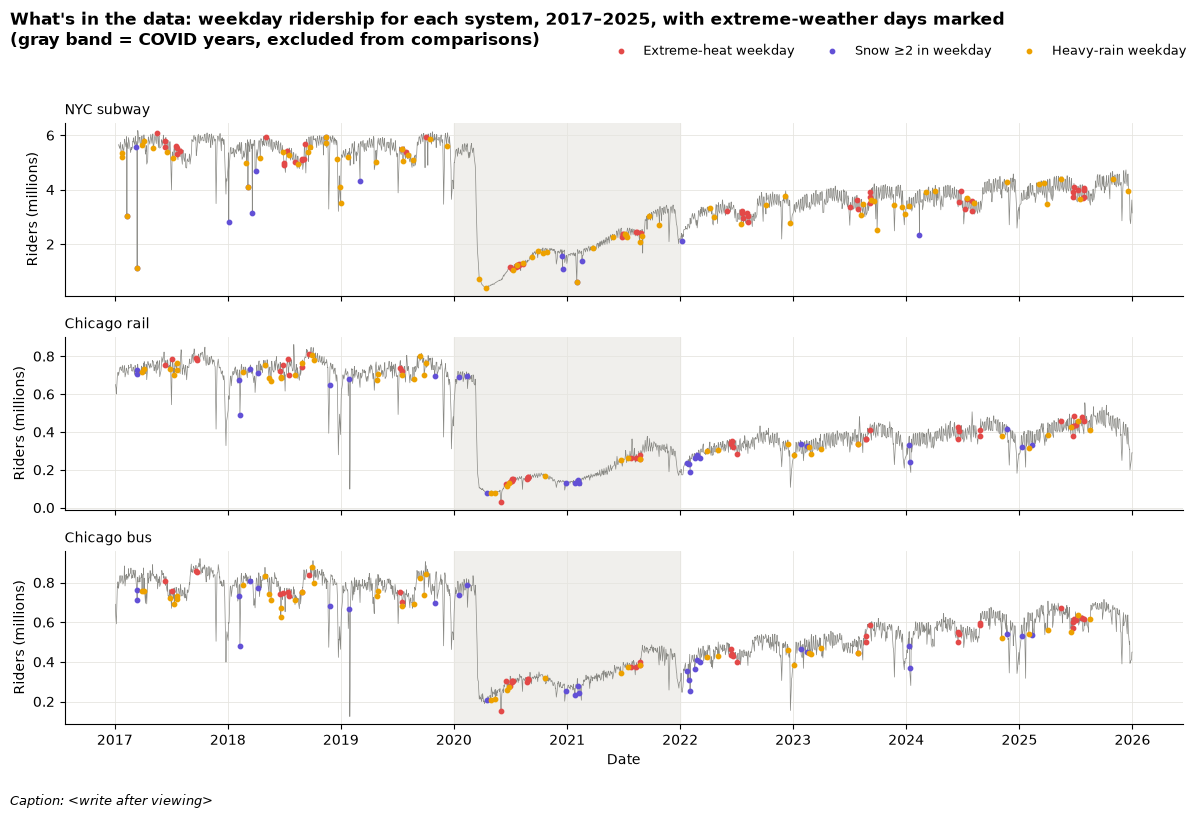

period            covid  post_covid  pre_covid
mode                                          
Chicago bus    323500.0    537644.0   796682.0
Chicago rail   172408.0    380250.0   738412.0
NYC subway    1848418.0   3717874.0  5645394.0


In [184]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": .6, "axes.axisbelow": True, "font.size": 10})
MCOL = {"NYC subway": "#2a78d6", "Chicago rail": "#eb6834", "Chicago bus": "#1baf7a"}
ECOL = {"extreme_heat": "#e34948", "snow_2in": "#6250d6", "heavy_rain": "#eda100"}
PCOL = {"pre_covid": "#9ec5f4", "post_covid": "#1c5cab"}
PLAB = {"pre_covid": "2017–19", "post_covid": "2022–25"}

def caption(fig, text, y=-.06):
    fig.text(.01, y, text, fontsize=9, style="italic")

# P1 Overview
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, m in zip(axes, MODES):
    x = mode_day[(mode_day["mode"] == m) & (mode_day.day_type == "W")].set_index("date").sort_index()
    ax.plot(x.index, x.ridership / 1e6, color="#8a8a85", lw=.5)
    for ev, lab in [("extreme_heat", "Extreme-heat weekday"), ("snow_2in", "Snow ≥2 in weekday"), ("heavy_rain", "Heavy-rain weekday")]:
        e = x[x[ev].astype(bool)]
        ax.scatter(e.index, e.ridership / 1e6, s=10, color=ECOL[ev], zorder=3, label=lab)
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), color="#f0efec", zorder=0)
    ax.set_title(m, loc="left", fontsize=10); ax.set_ylabel("Riders (millions)")
axes[-1].set_xlabel("Date")
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, ncol=3, loc="upper right", bbox_to_anchor=(1, 1.0), fontsize=9)
fig.suptitle("What's in the data: weekday ridership for each system, 2017–2025, with extreme-weather days marked\n(gray band = COVID years, excluded from comparisons)",
             x=.01, ha="left", fontweight="bold", y=1.03)
caption(fig, "Caption: <write after viewing>", y=-.03)
fig.tight_layout(); fig.savefig(FIG_DIR / "P1_overview.png", dpi=150, bbox_inches="tight"); plt.show()
print(mode_day[mode_day.day_type == "W"].groupby(["mode", "period"])["ridership"].median().unstack().round(0))

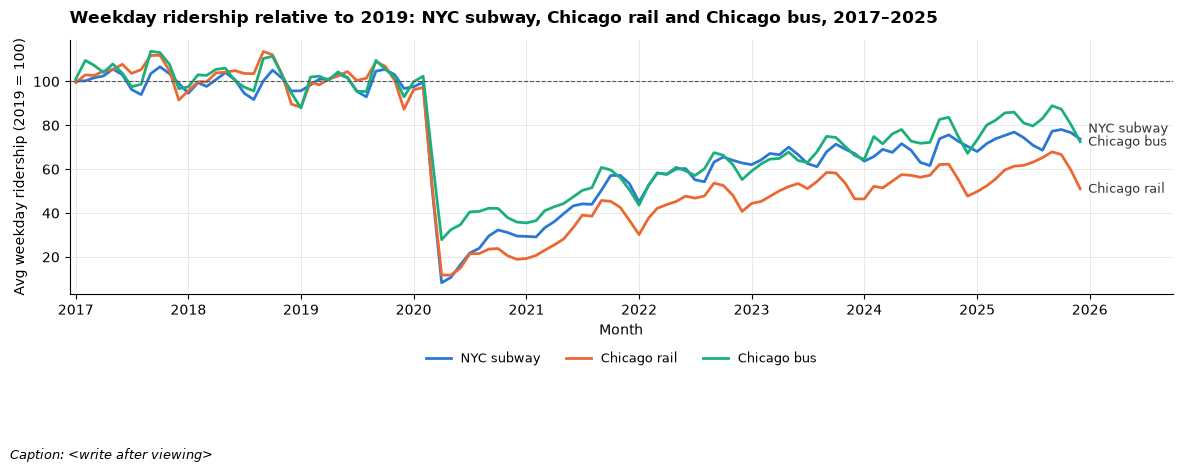

2025 level vs 2019 (=100): {'Chicago bus': 82.0, 'Chicago rail': 60.0, 'NYC subway': 74.0}


In [191]:
# P2 Trend: recovery vs 2019
w = mode_day[(mode_day.day_type == "W") & mode_day.valid].copy()
w["month"] = w["date"].dt.to_period("M").dt.to_timestamp()
mm = w.groupby(["mode", "month"])["ridership"].mean().unstack(0)
idx = mm / mm[mm.index.year == 2019].mean() * 100
fig, ax = plt.subplots(figsize=(12, 4))
for m in MODES:
    ax.plot(idx.index, idx[m], color=MCOL[m], lw=2, label=m)
last = sorted(((idx[m].dropna().iloc[-1], m) for m in MODES))
prev = None
for y, m in last:                                  # nudge end labels apart so they don't overlap
    if prev is not None and y - prev < 6: y = prev + 6
    ax.text(idx.index[-1], y, "  " + m, color="#333", va="center", fontsize=9); prev = y
ax.axhline(100, color="#555", lw=.8, ls="--")
ax.set_xlim(idx.index[0] - pd.Timedelta(days=20), idx.index[-1] + pd.Timedelta(days=300))
ax.set_ylabel("Avg weekday ridership (2019 = 100)"); ax.set_xlabel("Month")
ax.set_title("Weekday ridership relative to 2019: NYC subway, Chicago rail and Chicago bus, 2017–2025", loc="left", fontweight="bold", pad=12)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.18), fontsize=9)
caption(fig, "Caption: <write after viewing>", y=-.16)
fig.tight_layout(); fig.savefig(FIG_DIR / "P2_recovery_trend.png", dpi=150, bbox_inches="tight"); plt.show()
print("2025 level vs 2019 (=100):", idx[idx.index.year == 2025].mean().round(0).to_dict())

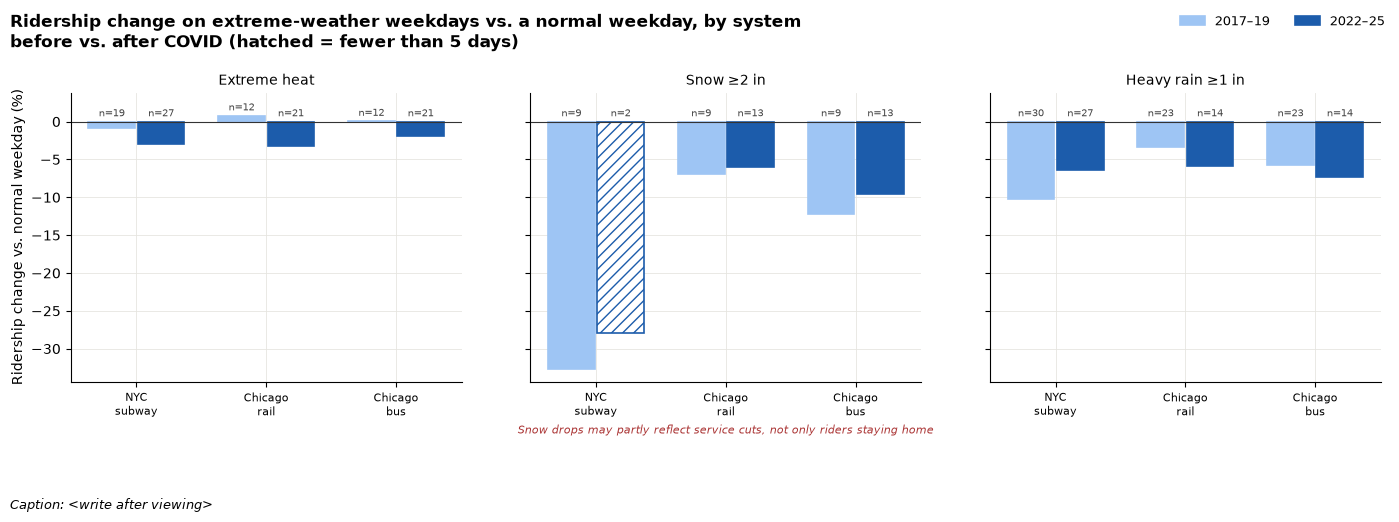

                                mean_pct               n_days          
period                        post_covid pre_covid post_covid pre_covid
event            group                                                 
Extreme heat     Chicago bus        -1.9       0.1       21.0      12.0
                 Chicago rail       -3.3       0.8       21.0      12.0
                 NYC subway         -3.0      -0.8       27.0      19.0
Heavy rain ≥1 in Chicago bus        -7.3      -5.7       14.0      23.0
                 Chicago rail       -5.8      -3.3       14.0      23.0
                 NYC subway         -6.4     -10.3       27.0      30.0
Snow ≥2 in       Chicago bus        -9.5     -12.2       13.0       9.0
                 Chicago rail       -6.0      -6.9       13.0       9.0
                 NYC subway        -28.0     -32.7        2.0       9.0


In [186]:
def bars(summary, groups, show, title, fname, labels=None, note_snow=True, rows=False, split_at=None):
    if rows:
        fig, axes = plt.subplots(len(show), 1, figsize=(14, 3.4 * len(show)), sharex=True, sharey=True)
    else:
        fig, axes = plt.subplots(1, len(show), figsize=(14, 4.6), sharey=True)
    x = np.arange(len(groups))
    for ax, ev in zip(axes, show):
        s = summary[summary.event == ev].set_index(["group", "period"])
        for j, p in enumerate(PERIODS):
            xs = x + (j - .5) * .38
            for k, (xi, g) in enumerate(zip(xs, groups)):
                v, n = s.loc[(g, p), "mean_pct"], s.loc[(g, p), "n_days"]
                ok = n >= 5 and pd.notna(v)
                ax.bar(xi, v if pd.notna(v) else 0, .36, color=PCOL[p] if ok else "white", edgecolor=PCOL[p],
                       hatch=None if ok else "///", linewidth=1.2, label=PLAB[p] if k == 0 else None)
                ax.text(xi, (max(v, 0) if pd.notna(v) else 0) + .4, f"n={n}", ha="center", va="bottom", fontsize=7, color="#444")
        ax.axhline(0, color="#333", lw=.8)
        ax.set_xticks(x, labels or groups, fontsize=8)
        ax.set_title(ev, fontsize=10, loc="left" if rows else "center")
        if split_at:
            ax.axvline(split_at - .5, color="#999", lw=1, ls="--")
    if split_at:   # city labels above the first panel, centred over each city's groups
        tr = axes[0].get_xaxis_transform()
        axes[0].text((split_at - 1) / 2, 1.04, "New York City (subway)", transform=tr, ha="center", fontsize=9, color="#444", fontweight="bold")
        axes[0].text(split_at + (len(groups) - split_at - 1) / 2, 1.04, "Chicago ('L' rail)", transform=tr, ha="center", fontsize=9, color="#444", fontweight="bold")
    for ax in (axes if rows else axes[:1]):
        ax.set_ylabel("Change vs. normal weekday (%)" if rows else "Ridership change vs. normal weekday (%)")
    for ax in axes: ax.set_xlabel("")
    top = np.nanmax([summary.loc[summary.event.isin(show), "mean_pct"].max(), 0])
    axes[0].set_ylim(top=top + 3)
    if note_snow:
        i = [k for k, e in enumerate(show) if "Snow" in e][0]
        note = "Snow drops may partly reflect service cuts, not only riders staying home"
        if rows:
            axes[i].set_title(note, loc="right", fontsize=8, style="italic", color="#a33")
        else:
            axes[i].text(.5, -.18, note, transform=axes[i].transAxes, ha="center", fontsize=8, style="italic", color="#a33")
    fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, ncol=2, loc="upper right", bbox_to_anchor=(1, 1.0), fontsize=9)
    fig.suptitle(title, x=.01, ha="left", fontweight="bold")
    caption(fig, "Caption: <write after viewing>", y=-.03 if rows else -.1)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight"); plt.show()

SHOW = ["Extreme heat", "Snow ≥2 in", "Heavy rain ≥1 in"]
# P3 Comparison across systems
bars(sum_mode, MODES, SHOW,
    "Ridership change on extreme-weather weekdays vs. a normal weekday, by system\nbefore vs. after COVID (hatched = fewer than 5 days)",
     "P3_systems_comparison.png", labels=["NYC\nsubway", "Chicago\nrail", "Chicago\nbus"])
print(sum_mode[sum_mode.event.isin(SHOW)].pivot_table(index=["event", "group"], columns="period",
      values=["mean_pct", "n_days"]).round(1).to_string())

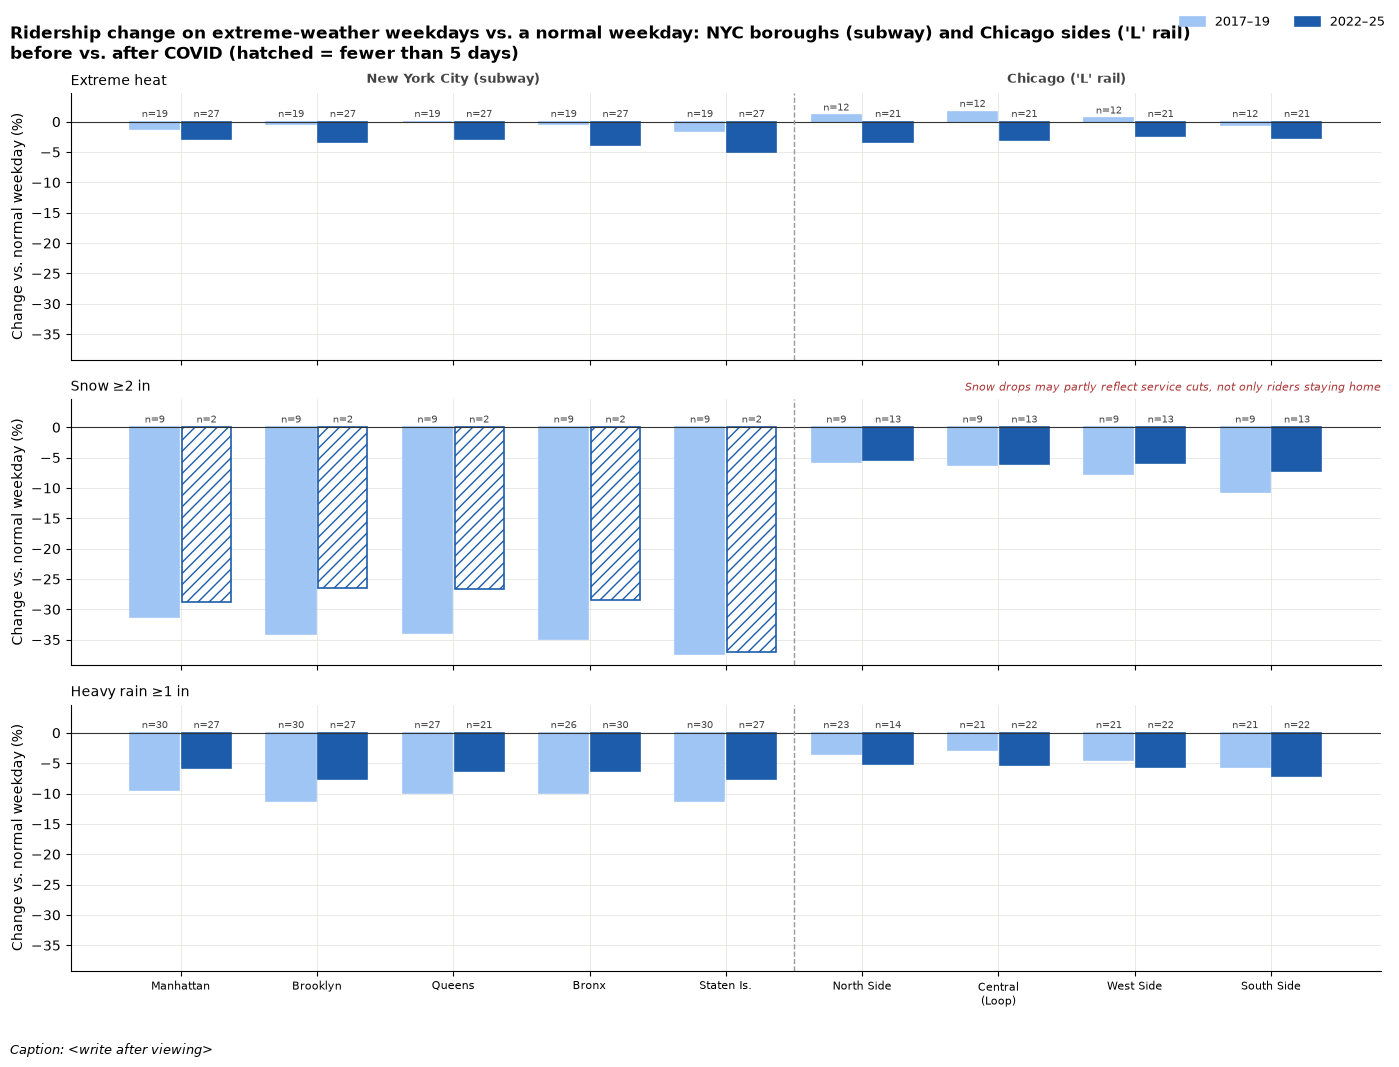

                                      mean_pct               n_days          
period                              post_covid pre_covid post_covid pre_covid
event            group                                                       
Extreme heat     Bronx                    -3.8      -0.4       27.0      19.0
                 Brooklyn                 -3.4      -0.4       27.0      19.0
                 Chicago Central          -3.1       1.7       21.0      12.0
                 Chicago North Side       -3.3       1.1       21.0      12.0
                 Chicago South Side       -2.7      -0.5       21.0      12.0
                 Chicago West Side        -2.3       0.6       21.0      12.0
                 Manhattan                -2.8      -1.2       27.0      19.0
                 Queens                   -2.8      -0.1       27.0      19.0
                 Staten Island            -5.0      -1.5       27.0      19.0
Heavy rain ≥1 in Bronx                    -6.3      -9.9       3

In [187]:
# P4 Comparison across places: NYC boroughs and Chicago regions
bars(sum_area, AREAS, SHOW,
     "Ridership change on extreme-weather weekdays vs. a normal weekday: NYC boroughs (subway) and Chicago sides ('L' rail)\n"
     "before vs. after COVID (hatched = fewer than 5 days)",
     "P4_areas_nyc_chicago.png", rows=True, split_at=len(BOROUGHS),
     labels=["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Is.", "North Side", "Central\n(Loop)", "West Side", "South Side"])
print(sum_area[sum_area.event.isin(SHOW)].pivot_table(index=["event", "group"], columns="period",
      values=["mean_pct", "n_days"]).round(1).to_string())

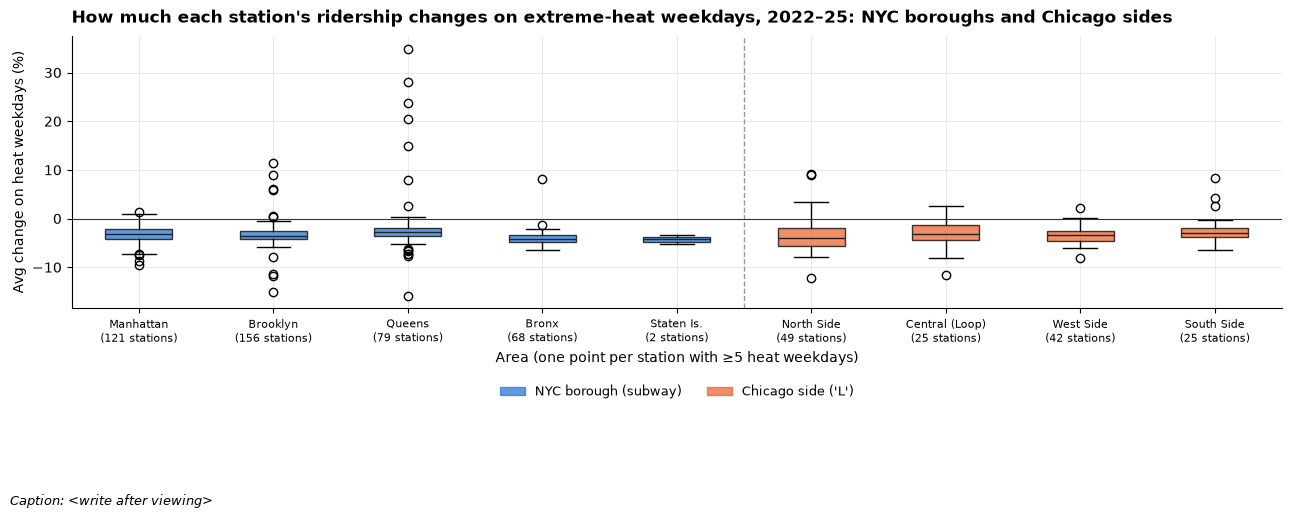

Five stations per area losing the most riders on heat weekdays:
city               area station_id                         station_name  mean  size     community_area
 NYC              Bronx        370                      Whitlock Av (6)  -6.5    27                NaN
 NYC              Bronx        380 Bedford Park Blvd-Lehman College (4)  -6.3    27                NaN
 NYC              Bronx        425                Bronx Park East (2,5)  -5.7    27                NaN
 NYC              Bronx        421                    Gun Hill Rd (2,5)  -5.7    27                NaN
 NYC              Bronx        372                      Longwood Av (6)  -5.7    27                NaN
 NYC           Brooklyn        284                        Nassau Av (G) -15.0    26                NaN
 NYC           Brooklyn        288            Myrtle-Willoughby Avs (G) -11.7    25                NaN
 NYC           Brooklyn        283                    Greenpoint Av (G) -11.5    25                NaN
 NYC     

In [188]:
# P5 Distribution: how stations differ on extreme-heat weekdays (2022–25)
heat = res_st[res_st.extreme_heat.astype(bool) & (res_st.period == "post_covid")]
per_st = heat.groupby(["city", "area", "station_id", "station_name"])["pct_change"].agg(mean="mean", size="count").reset_index()
per_st["community_area"] = per_st["station_id"].map(cta_st_lookup["community_area"])   # Chicago only
per_st = per_st[per_st["size"] >= 5]
CITY_C = {"NYC": "#2a78d6", "CHI": "#eb6834"}
fig, ax = plt.subplots(figsize=(13, 4.4))
data = [per_st.loc[per_st.area == a, "mean"].dropna() for a in AREAS]
bp = ax.boxplot(data, patch_artist=True, widths=.5, medianprops=dict(color="#222"))
for patch, a in zip(bp["boxes"], AREAS):
    patch.set_facecolor(CITY_C["CHI" if a.startswith("Chicago") else "NYC"]); patch.set_alpha(.75)
short = [a.replace("Chicago ", "").replace("Central", "Central (Loop)").replace("Staten Island", "Staten Is.") for a in AREAS]
ax.set_xticks(range(1, len(AREAS) + 1), [f"{a}\n({len(v)} stations)" for a, v in zip(short, data)], fontsize=8)
ax.axvline(len(BOROUGHS) + .5, color="#999", lw=1, ls="--")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CITY_C["NYC"], alpha=.75, label="NYC borough (subway)"),
                   Patch(color=CITY_C["CHI"], alpha=.75, label="Chicago side ('L')")],
          frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.24), fontsize=9)
ax.axhline(0, color="#333", lw=.8)
ax.set_ylabel("Avg change on heat weekdays (%)"); ax.set_xlabel("Area (one point per station with ≥5 heat weekdays)")
ax.set_title("How much each station's ridership changes on extreme-heat weekdays, 2022–25: NYC boroughs and Chicago sides",
             loc="left", fontweight="bold", pad=10)
caption(fig, "Caption: <write after viewing>", y=-.16)
fig.tight_layout(); fig.savefig(FIG_DIR / "P5_station_distribution.png", dpi=150, bbox_inches="tight"); plt.show()
top5 = per_st.sort_values("mean").groupby("area").head(5).sort_values(["area", "mean"])
top5.to_csv(CLEAN_DIR / "result_top5_heat_losers_by_area.csv", index=False)
print("Five stations per area losing the most riders on heat weekdays:"); print(top5.round(1).to_string(index=False))

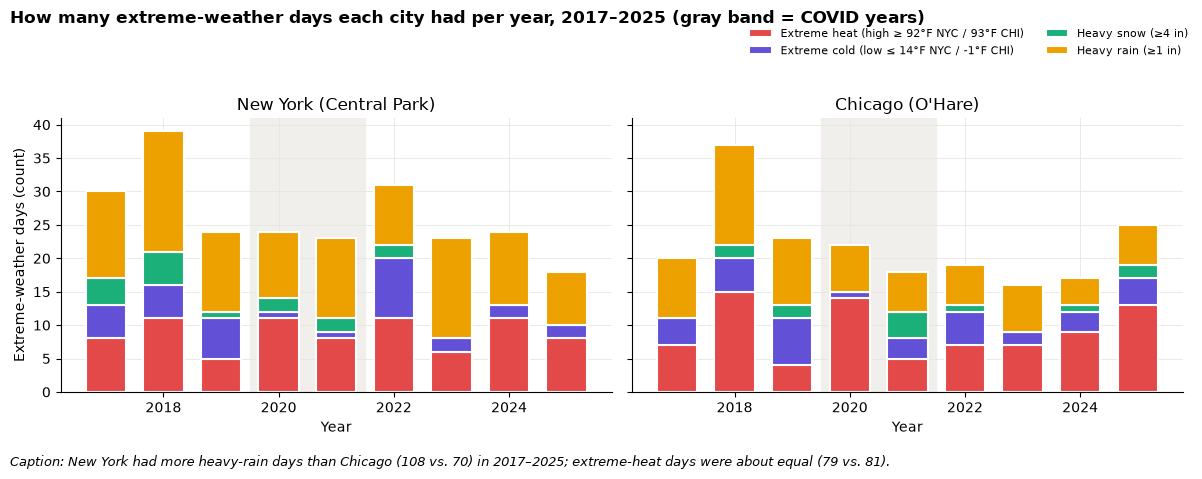

      extreme_heat  extreme_cold  heavy_snow  heavy_rain
city                                                    
CHI             81            34          12          70
NYC             79            33          16         108


In [189]:
# P6 Context: extreme-weather days per year (from the NOAA notebook's Chart 1)
FLAGS = ["extreme_heat", "extreme_cold", "heavy_snow", "heavy_rain"]
FLAG_C = {"extreme_heat": "#e34948", "extreme_cold": "#6250d6", "heavy_snow": "#1baf7a", "heavy_rain": "#eda100"}
LABEL = {"extreme_heat": f"Extreme heat (high ≥ {TH['NYC']['heat']:.0f}°F NYC / {TH['CHI']['heat']:.0f}°F CHI)",
         "extreme_cold": f"Extreme cold (low ≤ {TH['NYC']['cold']:.0f}°F NYC / {TH['CHI']['cold']:.0f}°F CHI)",
         "heavy_snow": "Heavy snow (≥4 in)", "heavy_rain": "Heavy rain (≥1 in)"}
cdw = city_day[city_day.period != "buffer"].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
counts = cdw.groupby(["city", "year"])[FLAGS].sum()
for ax, cty in zip(axes, ["NYC", "CHI"]):
    c = counts.loc[cty]; bottom = np.zeros(len(c))
    for f in FLAGS:
        ax.bar(c.index, c[f], bottom=bottom, color=FLAG_C[f], label=LABEL[f], edgecolor="white", linewidth=1.5, width=.7)
        bottom += c[f].values
    ax.set_title({"NYC": "New York (Central Park)", "CHI": "Chicago (O'Hare)"}[cty])
    ax.set_xlabel("Year"); ax.axvspan(2019.5, 2021.5, color="#f0efec", zorder=0)
axes[0].set_ylabel("Extreme-weather days (count)")
fig.legend(*axes[1].get_legend_handles_labels(), frameon=False, ncol=2, loc="upper right", bbox_to_anchor=(1, 1.08), fontsize=8)
fig.suptitle("How many extreme-weather days each city had per year, 2017–2025 (gray band = COVID years)",
             x=.01, ha="left", fontweight="bold", y=1.1)
caption(fig, "Caption: New York had more heavy-rain days than Chicago (108 vs. 70) in 2017–2025; extreme-heat days were about equal (79 vs. 81).", y=-.04)
fig.tight_layout(); fig.savefig(FIG_DIR / "P6_extreme_days_per_year.png", dpi=150, bbox_inches="tight"); plt.show()
print(counts.groupby("city").sum())